# DBMS Fundamentals: Transactions and Concurrency Control

> **Who is this for:** anyone who has written a few SQL statements and wonders what happens when *many* programs use the same database at once, or when the power fails halfway through an update. It is also written for BS/MS students revising the "transactions" and "concurrency control" chapters for exams and interviews.
>
> **What you will learn:**
> - what a **transaction** is, its **states**, and the **ACID** properties (bank-transfer demo in SQLite, including a real simulated crash)
> - **schedules**, **conflicts** (RW, WR, WW) and the classic **anomalies** (lost update, dirty read, unrepeatable read, phantom), reproduced by a simulator you write
> - **conflict serializability** (precedence graph) and **view serializability**
> - **recoverable, cascadeless and strict** schedules (with a classifier)
> - **lock-based protocols**: shared/exclusive locks, **2PL**, **strict 2PL**, **rigorous 2PL**, simulated on real schedules
> - **deadlocks**: wait-for graphs, detection, **wait-die**, **wound-wait** and timeouts
> - the **tree protocol**, **multiple-granularity locking** (IS, IX, SIX)
> - **timestamp ordering**, **Thomas' write rule**, **optimistic (validation)** concurrency control and **MVCC**
> - SQL **isolation levels**, and what SQLite actually does with two connections ("database is locked")
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb), [SQL fundamentals](../01_sql/01_sql_fundamentals.ipynb) (its transaction section is the practical starting point for this notebook), and [04_functional_dependencies_and_normalization.ipynb](04_functional_dependencies_and_normalization.ipynb) from this module (recommended, not required).
>
> **Time needed:** about 3 hours (plus practice problems).
>
> **Runs on:** CPU, no API key, no internet. Uses only Python's standard library, `sqlite3`, pandas, matplotlib and networkx.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

A **transaction** is a group of database changes that must happen completely or not at all. Paying by card feels like one step to you, but the bank must take money from your account and add it to the shop's; if the power fails in the middle, the money must not vanish. The database must also cope with many people using it at once, like two cashiers selling the last concert ticket at the same moment: without care, both sales go through. **Concurrency control** is the set of tricks that stops this, for example **locks** (only the person holding the pen may write in a shared notebook) or **versions** (readers look at a photo of the data while someone else edits it). The guarantees are summed up as **ACID**: all-or-nothing, rules always kept, users not getting in each other's way, and saved changes never lost. Banks, ticket sites, feature stores and AI agents that act on shared data all rely on this.

**Tiny example.** An account holds 100. Ann withdraws 50 while Ben deposits 20, so the right final balance is 100 − 50 + 20 = 70. Both read 100 at the same moment; Ann writes 100 − 50 = 50, then Ben writes 100 + 20 = 120. The final balance is 120, and Ann's withdrawal has been lost. With locking, Ben's update has to wait (or retry) until Ann is finished, so he reads 50 and writes 70, which is correct.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Transaction | a group of changes: all of them happen or none do | a bank transfer, a ticket purchase, a model-registry update |
| Lock | a "do not touch, I'm using it" sign on a piece of data | two clerks updating one account; `database is locked` errors in SQLite |
| MVCC / snapshot | readers see a frozen photo of the data while writers carry on | PostgreSQL; Delta Lake and Iceberg tables that training jobs read while new data arrives |

## Contents

1. Transactions: concept, states, ACID (SQLite bank transfer, rollback, simulated crash)
2. Schedules and conflicts
3. Anomalies, reproduced by a scheduler simulator
4. Conflict serializability (precedence graph) and view serializability
5. Recoverable, cascadeless and strict schedules
6. Lock-based protocols: S/X locks, 2PL, strict 2PL, rigorous 2PL (simulated)
7. Deadlocks: wait-for graph, detection, wait-die, wound-wait, timeouts
8. Graph-based (tree) protocol and multiple-granularity locking
9. Timestamp ordering and Thomas' write rule
10. Optimistic (validation-based) concurrency control and MVCC
11. SQL isolation levels, and SQLite with two connections
12. How this connects to modern AI, recap, practice problems

In [1]:
import sqlite3                                   # real transactions
import os, sys, shutil, tempfile, subprocess     # temp files and a crashing child process
import threading, time                           # a second writer for the locking demo
import random, re                                # random schedules, parsing schedules
from collections import namedtuple, defaultdict, deque
from itertools import permutations
import heapq                                     # deterministic topological sort
import math                                      # node positions for drawings
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

random.seed(0)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
WORKDIR = tempfile.mkdtemp(prefix="txn_demo_")   # all database files go here (deleted at the end)
print("sqlite", sqlite3.sqlite_version, "| pandas", pd.__version__, "| networkx", nx.__version__)

sqlite 3.45.1 | pandas 2.3.3 | networkx 3.7


## 1. Transactions

> 💡 **In plain English:** a transaction groups several changes so they all happen or none do, even if the program crashes halfway.

**Analogy.** Paying for groceries by card is *one* action for you, but several steps for the bank: check the balance, take money from your account, add it to the shop's account, write a record. If the system crashes after taking your money but before paying the shop, the money must not vanish. Either *all* the steps happen or *none* do.

**Definition.** A **transaction** is a unit of program execution that accesses and possibly updates data items, and that the DBMS treats as a single, indivisible logical operation. It starts (`BEGIN`) and ends with either **`COMMIT`** (make all changes permanent) or **`ROLLBACK`/abort** (undo all of them).

### ACID

| Property | Meaning | Who guarantees it |
|---|---|---|
| **Atomicity** | all operations of the transaction happen, or none do | recovery system (undo log / rollback journal) |
| **Consistency** | a transaction run alone takes the database from one consistent state to another (constraints hold) | the application programmer + integrity constraints |
| **Isolation** | concurrent transactions do not see each other's intermediate states; the result equals *some* serial order | concurrency-control system (locks, timestamps, MVCC) |
| **Durability** | once committed, changes survive crashes | recovery system (log forced to stable storage) |

### Transaction states

| State | Meaning |
|---|---|
| **Active** | executing its reads and writes |
| **Partially committed** | the last statement has run, but the changes may still be only in memory |
| **Committed** | the commit record is safely on disk: the changes are durable |
| **Failed** | normal execution cannot continue (error, constraint violation, crash, deadlock victim) |
| **Aborted** | rolled back: the database is as if the transaction never ran; the system may **restart** or **kill** it |
| **Terminated** | (Elmasri) the transaction has left the system, after commit or abort |

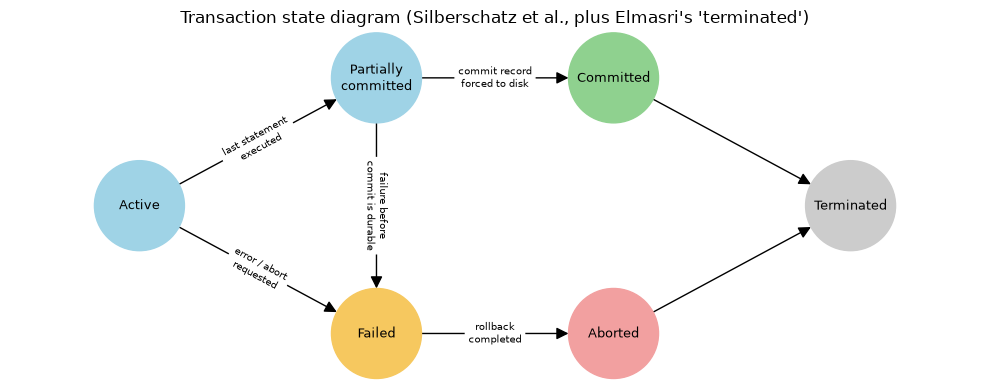

In [2]:
G = nx.DiGraph()
edges = [("Active", "Partially\ncommitted", "last statement\nexecuted"),
         ("Partially\ncommitted", "Committed", "commit record\nforced to disk"),
         ("Active", "Failed", "error / abort\nrequested"),
         ("Partially\ncommitted", "Failed", "failure before\ncommit is durable"),
         ("Failed", "Aborted", "rollback\ncompleted"),
         ("Committed", "Terminated", ""), ("Aborted", "Terminated", "")]
G.add_edges_from((a, b) for a, b, _ in edges)
pos = {"Active": (0, 0), "Partially\ncommitted": (2, 1), "Committed": (4, 1), "Failed": (2, -1),
       "Aborted": (4, -1), "Terminated": (6, 0)}
fig, ax = plt.subplots(figsize=(10, 4))
colors = {"Committed": "#8fd18f", "Aborted": "#f2a0a0", "Failed": "#f6c85f", "Terminated": "#cccccc"}
nx.draw_networkx_nodes(G, pos, node_size=4200, ax=ax, node_color=[colors.get(n, "#9fd3e6") for n in G])
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=18, node_size=4200)
nx.draw_networkx_edge_labels(G, pos, {(a, b): l for a, b, l in edges if l}, font_size=7.5, ax=ax)
ax.set_title("Transaction state diagram (Silberschatz et al., plus Elmasri's 'terminated')")
ax.axis("off"); ax.margins(0.12); plt.tight_layout(); plt.show()

### ACID in SQLite: a bank transfer

We create `account(name, balance)` with the integrity constraint `CHECK (balance >= 0)`. A transfer is two `UPDATE`s inside one transaction. Python's `with con:` block commits if the block finishes and **rolls back** if an exception escapes. Every scenario checks the consistency invariant "the total amount of money never changes".

In [3]:
bank_path = os.path.join(WORKDIR, "bank.db")
con = sqlite3.connect(bank_path)
con.executescript('''
CREATE TABLE account (name TEXT PRIMARY KEY, balance INTEGER NOT NULL CHECK (balance >= 0));
INSERT INTO account VALUES ('Alice', 100), ('Bob', 50);
''')
con.commit()

def balances(c=con):
    return dict(c.execute("SELECT name, balance FROM account ORDER BY name").fetchall())

def transfer(con, src, dst, amount):
    "Move money atomically: both updates happen, or neither does."
    with con:                                                              # BEGIN ... COMMIT / ROLLBACK
        con.execute("UPDATE account SET balance = balance - ? WHERE name = ?", (amount, src))
        cur = con.execute("UPDATE account SET balance = balance + ? WHERE name = ?", (amount, dst))
        if cur.rowcount != 1:                                              # destination does not exist
            raise ValueError(f"no account named {dst!r}")

TOTAL = sum(balances().values())
log = [("start", balances())]
transfer(con, "Alice", "Bob", 30);                                   log.append(("Alice→Bob 30: committed", balances()))
try:
    transfer(con, "Alice", "Bob", 500)                               # violates CHECK on the debit
except sqlite3.IntegrityError as e:
    log.append((f"Alice→Bob 500: rolled back ({e})", balances()))
try:
    transfer(con, "Alice", "Carol", 10)                              # debit succeeds, credit fails
except ValueError as e:
    log.append((f"Alice→Carol 10: rolled back ({e})", balances()))
for what, b in log:
    print(f"{what:65s} {b}   total = {sum(b.values())}")
    assert sum(b.values()) == TOTAL                                  # consistency invariant

start                                                             {'Alice': 100, 'Bob': 50}   total = 150
Alice→Bob 30: committed                                           {'Alice': 70, 'Bob': 80}   total = 150
Alice→Bob 500: rolled back (CHECK constraint failed: balance >= 0) {'Alice': 70, 'Bob': 80}   total = 150
Alice→Carol 10: rolled back (no account named 'Carol')            {'Alice': 70, 'Bob': 80}   total = 150


**What just happened?** The first transfer committed. The second violated the `CHECK` constraint, so SQLite raised `IntegrityError` and the `with` block rolled back. The third is the interesting one: Alice's debit **had already succeeded** inside the transaction when the credit failed, and the rollback undid it. Total money stayed 150 in every state: *atomicity* protected *consistency*.

### A real crash in the middle of a transaction

Exceptions are polite failures. A crash is not: the process simply disappears. We run a payroll batch in a **separate Python process** that pays 2,000 employees from the company account one row at a time and then calls `os._exit(1)` halfway through, without committing (like a power cut). A tiny page cache forces SQLite to write some of the uncommitted changes into the database file before the "crash", so the file on disk really is half-updated.

SQLite (in its default rollback-journal mode) copies every page it is about to change into `payroll.db-journal` first. On the next open, it finds this **hot journal** and copies the old pages back: the half-finished transaction is undone.

In [4]:
pay_path = os.path.join(WORKDIR, "payroll.db")
c = sqlite3.connect(pay_path)
c.execute("CREATE TABLE account (name TEXT PRIMARY KEY, balance INTEGER NOT NULL, note TEXT)")
c.execute("INSERT INTO account VALUES ('company', 1000000, '')")
c.executemany("INSERT INTO account VALUES (?, 0, ?)", [(f"emp{i:04d}", "x" * 200) for i in range(2000)])
c.commit(); c.close()

def money(path):
    c = sqlite3.connect(path)
    total, company = c.execute("SELECT SUM(balance), MAX(CASE WHEN name='company' THEN balance END) FROM account").fetchone()
    paid = c.execute("SELECT COUNT(*) FROM account WHERE name LIKE 'emp%' AND balance > 0").fetchone()[0]
    c.close()
    return {"total": total, "company": company, "employees paid": paid}

def run_child(commit):
    "Pay everyone in a child process; crash after 1,000 payments (or right after COMMIT)."
    code = f'''
import sqlite3, os
con = sqlite3.connect({pay_path!r}, isolation_level=None)
con.execute("PRAGMA cache_size = 5")          # tiny cache: dirty pages spill to the database file
con.execute("BEGIN")
for i in range(2000):
    con.execute("UPDATE account SET balance = balance - 100 WHERE name = 'company'")
    con.execute("UPDATE account SET balance = balance + 100 WHERE name = ?", (f"emp{{i:04d}}",))
    if i == 999 and not {commit}:
        os._exit(1)                           # CRASH: no commit, no clean shutdown
con.execute("COMMIT")
os._exit(1)                                   # crash right AFTER the commit
'''
    return subprocess.run([sys.executable, "-c", code]).returncode

print("before:              ", money(pay_path))
mtime = os.path.getmtime(pay_path)
rc = run_child(commit=False)
files = sorted(os.listdir(WORKDIR))
print(f"child exit code {rc}; files now: {[f for f in files if f.startswith('payroll')]}; "
      f"database file modified by the crashed transaction: {os.path.getmtime(pay_path) != mtime}")
after_crash = money(pay_path)                 # opening the database rolls the hot journal back
print("after crash + reopen:", after_crash, "| journal still there:", os.path.exists(pay_path + "-journal"))
assert after_crash == {"total": 1000000, "company": 1000000, "employees paid": 0}

rc = run_child(commit=True)
after_commit = money(pay_path)
print("after a crash *after* COMMIT:", after_commit)
assert after_commit == {"total": 1000000, "company": 800000, "employees paid": 2000}

before:               {'total': 1000000, 'company': 1000000, 'employees paid': 0}


child exit code 1; files now: ['payroll.db', 'payroll.db-journal']; database file modified by the crashed transaction: True
after crash + reopen: {'total': 1000000, 'company': 1000000, 'employees paid': 0} | journal still there: False


after a crash *after* COMMIT: {'total': 1000000, 'company': 800000, 'employees paid': 2000}


**What just happened?**
- The child process died with exit code 1 after paying 1,000 people. The database file *had* been modified and a journal file was left behind.
- Simply opening and reading the database made SQLite detect the hot journal, restore the original pages and delete the journal. Nobody was paid, the company kept its money: **atomicity** survived a real crash.
- In the second run the process crashed immediately *after* `COMMIT`. All 2,000 payments were still there: **durability**.

> ⚠️ **Common mistake:** thinking `sqlite3` in Python autocommits every statement. By default, the module opens a transaction implicitly before `INSERT`/`UPDATE`/`DELETE` and you must call `commit()` (or use `with con:`); if the program exits first, the changes are lost. Practical details are in [SQL fundamentals](../01_sql/01_sql_fundamentals.ipynb).

## 2. Schedules and conflicts

> 💡 **In plain English:** a schedule is the order in which the steps of several transactions actually run, and two steps clash if they touch the same item and at least one of them writes.

To study concurrency we abstract a transaction to its reads and writes of data items. We write

`r1(A)` = T1 reads A, `w2(B)` = T2 writes B, `c1` = T1 commits, `a2` = T2 aborts.

A **schedule** is a sequence of operations from several transactions that keeps each transaction's own order.
- **Serial schedule:** transactions run one after another, no interleaving. Always correct (each transaction preserves consistency), but slow.
- **Concurrent (interleaved) schedule:** operations of different transactions are mixed. Faster (CPU and disk overlap, short transactions are not stuck behind long ones), but may be wrong.

Two operations **conflict** if they (1) belong to different transactions, (2) access the same item, and (3) at least one is a write:

| pair (first, second) | name | why the order matters |
|---|---|---|
| r_i(X), w_j(X) | **RW** conflict | T_i must read the old value, not T_j's |
| w_i(X), r_j(X) | **WR** conflict | T_j reads T_i's value (source of dirty reads) |
| w_i(X), w_j(X) | **WW** conflict | decides which value survives (source of lost updates) |
| r_i(X), r_j(X) | no conflict | reads can be swapped freely |

In [5]:
Op = namedtuple("Op", "kind txn item")      # kind in 'r', 'w', 'c', 'a'

def parse(s):
    "'r1(A) w2(A) c1' -> [Op('r',1,'A'), Op('w',2,'A'), Op('c',1,None)]"
    if not isinstance(s, str):
        return list(s)
    return [Op(k, int(t), item) for k, t, item in re.findall(r"([rwca])(\d+)(?:\(\s*(\w+)\s*\))?", s)]

def op_str(o):
    return f"{o.kind}{o.txn}({o.item})" if o.item else f"{o.kind}{o.txn}"

def show(S):
    return " ".join(op_str(o) for o in parse(S))

def as_table(S):
    "Textbook layout: one column per transaction, time flows downwards."
    S = parse(S)
    txns = sorted({o.txn for o in S})
    return pd.DataFrame([{f"T{t}": (op_str(o) if o.txn == t else "") for t in txns} for o in S],
                        index=range(1, len(S) + 1))

def conflicts(S):
    "All conflicting pairs (i, j, type) with i < j."
    S = parse(S)
    out = []
    for i in range(len(S)):
        for j in range(i + 1, len(S)):
            a, b = S[i], S[j]
            if a.kind in "rw" and b.kind in "rw" and a.txn != b.txn and a.item == b.item and "w" in (a.kind + b.kind):
                out.append((i, j, (a.kind + b.kind).upper()))
    return out

S_demo = "r1(A) w1(A) r2(A) w2(A) r1(B) w1(B) r2(B) w2(B) c1 c2"
print(as_table(S_demo).T.to_string())
print("\nconflicting pairs:")
for i, j, kind in conflicts(S_demo):
    print(f"  {op_str(parse(S_demo)[i]):6s} before {op_str(parse(S_demo)[j]):6s}  -> {kind}")

       1      2      3      4      5      6      7      8   9   10
T1  r1(A)  w1(A)                r1(B)  w1(B)                c1    
T2                r2(A)  w2(A)                r2(B)  w2(B)      c2

conflicting pairs:
  r1(A)  before w2(A)   -> RW
  w1(A)  before r2(A)   -> WR
  w1(A)  before w2(A)   -> WW
  r1(B)  before w2(B)   -> RW
  w1(B)  before r2(B)   -> WR
  w1(B)  before w2(B)   -> WW


## 3. The classic anomalies, reproduced

> 💡 **In plain English:** with no control at all, mixing two transactions' steps loses updates, shows data that was never saved, or changes an answer between two reads; we make each problem happen.

Below is a tiny "database" with no concurrency control at all. Each transaction is a small program (read, compute, write, commit/abort) and an **interleaving** says whose step runs next. The simulator prints a trace: what each transaction did and the database state after every step.

| Anomaly | Pattern | What goes wrong |
|---|---|---|
| **Lost update** | r1(A) r2(A) w1(A) w2(A) | T2 overwrites T1's write, computed from a stale value (WW after two reads) |
| **Dirty read** (temporary update) | w1(A) r2(A) a1 | T2 uses a value that, after T1 aborts, never officially existed (WR on uncommitted data) |
| **Unrepeatable read** | r1(A) w2(A) c2 r1(A) | T1 reads the same item twice and gets two different values (RW then WR) |
| **Phantom** | T1: `SELECT … WHERE p`; T2: `INSERT` a row satisfying p; T1: same `SELECT` | a *new row* appears; locking existing rows cannot prevent it |

In [6]:
MISSING = object()                      # marker: "this key did not exist" (for undoing inserts)

def simulate(programs, interleaving, db, show_keys=None):
    "Run transaction programs step by step, in the given interleaving, with NO concurrency control."
    db, local = dict(db), {t: {"reads": []} for t in programs}
    pc, undo = {t: 0 for t in programs}, {t: [] for t in programs}
    trace = []
    for t in interleaving:
        step = programs[t][pc[t]]; pc[t] += 1
        kind = step[0]
        if kind == "read":                                         # local copy := database value
            item = step[1]; local[t][item] = db[item]; local[t]["reads"].append(db[item])
            desc = f"read({item}) = {db[item]}"
        elif kind == "write":                                      # database := f(local copies)
            item, f = step[1], step[2]; val = f(local[t])
            undo[t].append((item, db.get(item, MISSING))); db[item] = val; local[t][item] = val
            desc = f"write({item}) := {val}"
        elif kind == "scan":                                       # SELECT key WHERE predicate
            name, pred = step[1], step[2]
            hits = sorted(k for k, v in db.items() if pred(k, v)); local[t][name] = hits
            local[t]["reads"].append(len(hits)); desc = f"SELECT count(*) WHERE … = {len(hits)}"
        elif kind == "insert":
            key, val = step[1], step[2]; undo[t].append((key, MISSING)); db[key] = val
            desc = f"INSERT {key}={val}"
        elif kind == "commit":
            undo[t] = []; desc = "commit"
        elif kind == "abort":                                      # restore before-images, newest first
            for key, old in reversed(undo[t]):
                if old is MISSING: db.pop(key, None)
                else: db[key] = old
            undo[t] = []; desc = "ABORT (rollback)"
        keys = show_keys or sorted(db)
        trace.append({**{tt: (desc if tt == t else "") for tt in programs},
                      "database after step": ", ".join(f"{k}={db[k]}" for k in keys if k in db)})
    print(pd.DataFrame(trace, index=range(1, len(trace) + 1)).to_string())
    return db, local

In [7]:
print("LOST UPDATE: T1 withdraws 50, T2 deposits 20; correct final A = 100 - 50 + 20 = 70")
T1 = [("read", "A"), ("write", "A", lambda L: L["A"] - 50), ("commit",)]
T2 = [("read", "A"), ("write", "A", lambda L: L["A"] + 20), ("commit",)]
db, _ = simulate({"T1": T1, "T2": T2}, ["T1", "T2", "T1", "T2", "T1", "T2"], {"A": 100})
print("final A =", db["A"], "-> T1's withdrawal was lost\n")
assert db["A"] == 120

print("DIRTY READ: T2 copies A into a report while T1's change is still uncommitted; T1 then aborts")
T1 = [("read", "A"), ("write", "A", lambda L: L["A"] - 50), ("abort",)]
T2 = [("read", "A"), ("write", "report", lambda L: L["A"]), ("commit",)]
db, _ = simulate({"T1": T1, "T2": T2}, ["T1", "T1", "T2", "T2", "T2", "T1"], {"A": 100, "report": 0})
print("A =", db["A"], "but the committed report says", db["report"], "-> T2 used a value that never existed\n")
assert db["A"] == 100 and db["report"] == 50

LOST UPDATE: T1 withdraws 50, T2 deposits 20; correct final A = 100 - 50 + 20 = 70
               T1               T2 database after step
1   read(A) = 100                                A=100
2                    read(A) = 100               A=100
3  write(A) := 50                                 A=50
4                  write(A) := 120               A=120
5          commit                                A=120
6                           commit               A=120
final A = 120 -> T1's withdrawal was lost

DIRTY READ: T2 copies A into a report while T1's change is still uncommitted; T1 then aborts
                 T1                   T2 database after step
1     read(A) = 100                          A=100, report=0
2    write(A) := 50                           A=50, report=0
3                           read(A) = 50      A=50, report=0
4                    write(report) := 50     A=50, report=50
5                                 commit     A=50, report=50
6  ABORT (rollback)           

In [8]:
print("UNREPEATABLE READ: T1 reads A twice; T2 changes A in between and commits")
T1 = [("read", "A"), ("read", "A"), ("commit",)]
T2 = [("read", "A"), ("write", "A", lambda L: L["A"] - 50), ("commit",)]
db, local = simulate({"T1": T1, "T2": T2}, ["T1", "T2", "T2", "T2", "T1", "T1"], {"A": 100})
print("T1 saw", local["T1"]["reads"], "for the same item inside ONE transaction\n")
assert local["T1"]["reads"] == [100, 50]

print("PHANTOM: T1 counts CS employees twice; T2 inserts a new CS employee in between")
is_cs = lambda k, v: k.startswith("emp") and v == "CS"
T1 = [("scan", "cs", is_cs), ("scan", "cs", is_cs), ("commit",)]
T2 = [("insert", "emp4", "CS"), ("commit",)]
db, local = simulate({"T1": T1, "T2": T2}, ["T1", "T2", "T2", "T1", "T1"],
                     {"emp1": "CS", "emp2": "CS", "emp3": "EE"})
print("T1's two identical queries returned", local["T1"]["reads"], "rows: a phantom row appeared")
assert local["T1"]["reads"] == [2, 3]

UNREPEATABLE READ: T1 reads A twice; T2 changes A in between and commits
              T1              T2 database after step
1  read(A) = 100                               A=100
2                  read(A) = 100               A=100
3                 write(A) := 50                A=50
4                         commit                A=50
5   read(A) = 50                                A=50
6         commit                                A=50
T1 saw [100, 50] for the same item inside ONE transaction

PHANTOM: T1 counts CS employees twice; T2 inserts a new CS employee in between
                            T1              T2                 database after step
1  SELECT count(*) WHERE … = 2                           emp1=CS, emp2=CS, emp3=EE
2                               INSERT emp4=CS  emp1=CS, emp2=CS, emp3=EE, emp4=CS
3                                       commit  emp1=CS, emp2=CS, emp3=EE, emp4=CS
4  SELECT count(*) WHERE … = 3                  emp1=CS, emp2=CS, emp3=EE, emp4=CS
5  

**What just happened?** Each anomaly appeared exactly as predicted: the final balance was 120 instead of 70 (lost update), a committed report holds 50 although A was never 50 after the abort (dirty read), T1 read A as 100 and then 50 (unrepeatable read), and T1's identical query returned 2 and then 3 rows (phantom). Note that in the phantom case T2 did not touch any row T1 had read, so locking *rows* cannot help; the system must lock the *predicate* (or an index range).

Every concurrency-control method in the rest of this notebook exists to rule out some or all of these.

## 4. Serializability

> 💡 **In plain English:** a mixed schedule is safe if it gives the same result as running the transactions one after another, and a simple arrow graph tells us whether it does.

A concurrent schedule is **correct** if it is equivalent to *some* serial schedule; such a schedule is **serializable**. Two notions of "equivalent" are used.

### 4.1 Conflict serializability

Two schedules are **conflict equivalent** if one can be turned into the other by swapping adjacent **non-conflicting** operations, i.e. they order every conflicting pair the same way. A schedule is **conflict serializable** if it is conflict equivalent to a serial schedule.

**Test (precedence graph).** Draw a node per transaction and an edge T_i → T_j whenever an operation of T_i conflicts with a *later* operation of T_j. The schedule is conflict serializable **iff the graph is acyclic**, and every **topological order** of the graph is an equivalent serial order.

| Schedule (Silberschatz) | Edges | Result |
|---|---|---|
| Schedule 3: `r1(A) w1(A) r2(A) w2(A) r1(B) w1(B) r2(B) w2(B)` | T1 → T2 only | serializable as T1, T2 |
| Schedule 4: `r1(A) r2(A) w2(A) r2(B) w1(A) r1(B) w1(B) w2(B)` | T1 → T2 (r1(A) before w2(A)) and T2 → T1 (w2(A) before w1(A)) | cycle: not serializable |

In [9]:
def precedence_graph(S):
    "Edges Ti -> Tj (with the items/conflict types that caused them); aborted transactions are ignored."
    S = parse(S)
    aborted = {o.txn for o in S if o.kind == "a"}
    S = [o for o in S if o.txn not in aborted]
    nodes = sorted({o.txn for o in S})
    edges = defaultdict(set)
    for i, j, kind in conflicts(S):
        edges[(S[i].txn, S[j].txn)].add(f"{kind}({S[i].item})")
    return nodes, dict(edges)

def find_cycle(nodes, edges):
    "Depth-first search with three colours; returns one cycle as a list of nodes, or None."
    adj = defaultdict(list)
    for a, b in edges:
        adj[a].append(b)
    colour, parent = {n: "white" for n in nodes}, {}
    def dfs(u):
        colour[u] = "grey"                                   # on the current DFS path
        for v in sorted(adj[u]):
            if colour[v] == "grey":                          # back edge u -> v closes a cycle
                cyc, x = [u], u
                while x != v:                                # walk back along the DFS path to v
                    x = parent[x]; cyc.append(x)
                return cyc[::-1]                             # v -> ... -> u (-> v)
            if colour[v] == "white":
                parent[v] = u
                found = dfs(v)
                if found: return found
        colour[u] = "black"                                  # finished
        return None
    for n in nodes:
        if colour[n] == "white":
            c = dfs(n)
            if c: return c
    return None

def topological_order(nodes, edges):
    "Kahn's algorithm, smallest ready transaction first (deterministic)."
    indeg = {n: 0 for n in nodes}; adj = defaultdict(list)
    for a, b in edges:
        adj[a].append(b); indeg[b] += 1
    ready = [n for n in nodes if indeg[n] == 0]; heapq.heapify(ready); order = []
    while ready:
        u = heapq.heappop(ready); order.append(u)
        for v in adj[u]:
            indeg[v] -= 1
            if indeg[v] == 0: heapq.heappush(ready, v)
    return order if len(order) == len(nodes) else None

def conflict_serializable(S, verbose=False):
    nodes, edges = precedence_graph(S)
    cyc = find_cycle(nodes, edges)
    if verbose:
        print(show(S))
        print("   edges:", ", ".join(f"T{a}→T{b} {sorted(l)}" for (a, b), l in sorted(edges.items())) or "none")
        print("   " + (f"CYCLE {' → '.join('T%d' % t for t in cyc + cyc[:1])}: NOT conflict serializable" if cyc
               else "acyclic: conflict serializable, equivalent serial order " + " → ".join(f"T{t}" for t in topological_order(nodes, edges))))
    return (False, cyc) if cyc else (True, topological_order(nodes, edges))

sched3 = "r1(A) w1(A) r2(A) w2(A) r1(B) w1(B) r2(B) w2(B)"
sched4 = "r1(A) r2(A) w2(A) r2(B) w1(A) r1(B) w1(B) w2(B)"
sched3t = "r1(X) r2(Z) r1(Z) r3(X) r3(Y) w1(X) w3(Y) r2(Y) w2(Z) w2(Y)"
assert conflict_serializable(sched3, verbose=True) == (True, [1, 2])
assert conflict_serializable(sched4, verbose=True)[0] is False
assert conflict_serializable(sched3t, verbose=True) == (True, [3, 1, 2])

r1(A) w1(A) r2(A) w2(A) r1(B) w1(B) r2(B) w2(B)
   edges: T1→T2 ['RW(A)', 'RW(B)', 'WR(A)', 'WR(B)', 'WW(A)', 'WW(B)']
   acyclic: conflict serializable, equivalent serial order T1 → T2
r1(A) r2(A) w2(A) r2(B) w1(A) r1(B) w1(B) w2(B)
   edges: T1→T2 ['RW(A)', 'RW(B)', 'WW(B)'], T2→T1 ['RW(A)', 'RW(B)', 'WW(A)']
   CYCLE T1 → T2 → T1: NOT conflict serializable
r1(X) r2(Z) r1(Z) r3(X) r3(Y) w1(X) w3(Y) r2(Y) w2(Z) w2(Y)
   edges: T1→T2 ['RW(Z)'], T3→T1 ['RW(X)'], T3→T2 ['RW(Y)', 'WR(Y)', 'WW(Y)']
   acyclic: conflict serializable, equivalent serial order T3 → T1 → T2


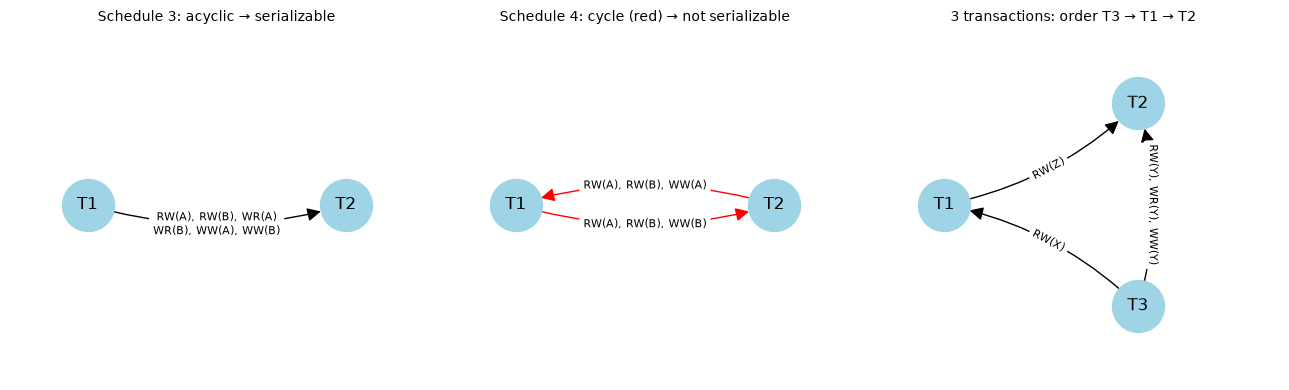

In [10]:
def draw_precedence(S, ax, title):
    nodes, edges = precedence_graph(S)
    G = nx.DiGraph(); G.add_nodes_from(f"T{n}" for n in nodes)
    G.add_edges_from((f"T{a}", f"T{b}") for a, b in edges)
    cyc = find_cycle(nodes, edges)
    cyc_edges = {(f"T{a}", f"T{b}") for a, b in zip(cyc, cyc[1:] + cyc[:1])} if cyc else set()
    k = len(nodes)                                            # nodes on a circle, T1 on the left
    pos = {f"T{n}": (-math.cos(2 * math.pi * i / k), math.sin(2 * math.pi * i / k)) for i, n in enumerate(nodes)}
    wrap = lambda l: "\n".join(", ".join(sorted(l)[i:i + 3]) for i in range(0, len(l), 3))
    nx.draw_networkx_nodes(G, pos, node_color="#9fd3e6", node_size=1400, ax=ax)
    nx.draw_networkx_labels(G, pos, ax=ax)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=20, node_size=1400,
                           connectionstyle="arc3,rad=0.15",
                           edge_color=["red" if e in cyc_edges else "black" for e in G.edges])
    nx.draw_networkx_edge_labels(G, pos, {(f"T{a}", f"T{b}"): wrap(l) for (a, b), l in edges.items()},
                                 font_size=8, ax=ax, connectionstyle="arc3,rad=0.15")
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.5, 1.5)
    ax.set_title(title, fontsize=10); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
draw_precedence(sched3, axes[0], "Schedule 3: acyclic → serializable")
draw_precedence(sched4, axes[1], "Schedule 4: cycle (red) → not serializable")
draw_precedence(sched3t, axes[2], "3 transactions: order T3 → T1 → T2")
plt.tight_layout(); plt.show()

In [11]:
# Brute-force check: is there a serial order that orders every conflicting pair the same way?
def conflict_serializable_bruteforce(S):
    S = [o for o in parse(S) if o.txn not in {x.txn for x in parse(S) if x.kind == "a"}]
    txns = sorted({o.txn for o in S}); pairs = conflicts(S)
    for order in permutations(txns):
        pos = {t: k for k, t in enumerate(order)}
        if all(pos[S[i].txn] < pos[S[j].txn] for i, j, _ in pairs):
            return True
    return False

def random_schedule(n_txn=3, items="AB", n_ops=(1, 3), commits=True, rng=random):
    "Random interleaving of random transactions (each keeps its own order)."
    progs = {t: [Op(rng.choice("rw"), t, rng.choice(items)) for _ in range(rng.randint(*n_ops))] + ([Op("c", t, None)] if commits else [])
             for t in range(1, n_txn + 1)}
    S, pcs = [], {t: 0 for t in progs}
    while any(pcs[t] < len(progs[t]) for t in progs):
        t = rng.choice([t for t in progs if pcs[t] < len(progs[t])])
        S.append(progs[t][pcs[t]]); pcs[t] += 1
    return S

n_cs = 0
for trial in range(1000):
    S = random_schedule(n_txn=random.randint(2, 4))
    ok, _ = conflict_serializable(S)
    assert ok == conflict_serializable_bruteforce(S), show(S)
    n_cs += ok
print(f"precedence-graph test == brute force on 1,000 random schedules ({n_cs} were conflict serializable)")

precedence-graph test == brute force on 1,000 random schedules (619 were conflict serializable)


**What just happened?** The three textbook schedules got the expected answers (asserted), the drawings show the cycle in Schedule 4 in red, and on 1,000 random schedules the graph test agreed with trying every serial order.

**Complexity.** Building the graph by comparing all pairs is O(n²) for n operations (O(n) per item with per-item lists); cycle detection and topological sort are O(V + E). Brute force is O(k! · n²) for k transactions.

### 4.2 View serializability

Two schedules S and S′ over the same transactions are **view equivalent** if:
1. **Initial reads:** if T_i reads the initial value of X in S, it does so in S′;
2. **Reads-from:** if T_i reads a value of X written by T_j in S, it does so in S′;
3. **Final writes:** the transaction that performs the last write of X in S also does so in S′.

A schedule is **view serializable** if it is view equivalent to a serial schedule. Every conflict-serializable schedule is view serializable; the converse fails only with **blind writes** (a write of X without a preceding read of X by that transaction). Testing view serializability is **NP-complete** (Papadimitriou, 1979), so real systems use conflict serializability.

**Example (Silberschatz, Schedule 9):** `r1(Q) w2(Q) w1(Q) w3(Q)`. The conflict graph has the cycle T1 → T2 → T1, yet the schedule is view equivalent to T1, T2, T3: T1 reads the initial Q in both, and T3 writes the final Q in both. T2's and T1's writes are overwritten by the blind write of T3, so nobody can tell their order apart.

In [12]:
def view_profile(S):
    "(reads-from map, final writer per item) of a schedule; key of a read = (txn, item, k-th read)."
    last, reads_from, count = {}, {}, defaultdict(int)
    for o in parse(S):
        if o.kind == "r":
            count[(o.txn, o.item)] += 1
            reads_from[(o.txn, o.item, count[(o.txn, o.item)])] = last.get(o.item)   # None = initial value
        elif o.kind == "w":
            last[o.item] = o.txn
    return reads_from, last

def serial(S, order):
    S = parse(S)
    return [o for t in order for o in S if o.txn == t and o.kind in "rw"]

def view_serializable(S):
    "Brute force over serial orders (the problem is NP-complete in general)."
    S = [o for o in parse(S) if o.kind in "rw"]
    target = view_profile(S)
    for order in permutations(sorted({o.txn for o in S})):
        if view_profile(serial(S, order)) == target:
            return True, list(order)
    return False, None

sched9 = "r1(Q) w2(Q) w1(Q) w3(Q)"
print(show(sched9), "-> conflict serializable:", conflict_serializable(sched9)[0],
      "| view serializable:", view_serializable(sched9))
assert conflict_serializable(sched9)[0] is False and view_serializable(sched9) == (True, [1, 2, 3])
assert view_serializable(sched4)[0] is False

for trial in range(600):                                 # conflict-serializable => view-serializable
    S = random_schedule(n_txn=3, commits=False)
    if conflict_serializable(S)[0]:
        assert view_serializable(S)[0], show(S)
print("every conflict-serializable random schedule was also view serializable")

r1(Q) w2(Q) w1(Q) w3(Q) -> conflict serializable: False | view serializable: (True, [1, 2, 3])
every conflict-serializable random schedule was also view serializable


## 5. Recoverable, cascadeless and strict schedules

> 💡 **In plain English:** if a transaction fails, others that used its data may have to be undone too; these classes describe how messy that clean-up can get.

Serializability ignores failures. If a transaction aborts, others that used its data must be dealt with too.

| Class | Definition | Why we want it |
|---|---|---|
| **Recoverable** | if T_j reads an item written by T_i, then T_i **commits before T_j commits** | otherwise a committed T_j depends on an aborted T_i: impossible to fix |
| **Cascadeless** (avoids cascading aborts, ACA) | every transaction reads only values written by **already committed** transactions | one abort never forces others to abort |
| **Strict** | no transaction **reads or writes** X until the last transaction that wrote X has committed or aborted | undo is a simple "restore the before-image" |

Strict ⊂ cascadeless ⊂ recoverable. Textbook examples (Elmasri and Navathe):

| Schedule | Class |
|---|---|
| S_c: `r1(X) w1(X) r2(X) r1(Y) w2(X) c2 a1` | **not recoverable** (T2 read from T1 and committed first) |
| S_d: `r1(X) w1(X) r2(X) r1(Y) w2(X) w1(Y) c1 c2` | recoverable, not cascadeless |
| S_e: `r1(X) w1(X) r2(X) r1(Y) w2(X) w1(Y) a1 a2` | recoverable, not cascadeless (T2 must cascade-abort) |
| `w1(X) w2(X) a1` | cascadeless (no reads) but **not strict** (T2 overwrote uncommitted X) |

In [13]:
def classify(S, verbose=False):
    "Return 'strict', 'cascadeless', 'recoverable' or 'not recoverable' (and the reasons)."
    S = parse(S)
    committed = set()
    writers = defaultdict(list)                # item -> stack of (non-aborted) writers
    reads_from = defaultdict(set)              # reader -> writers it read from
    rec = aca = strict = True; why = []
    for o in S:
        if o.kind in "rw":
            last = writers[o.item][-1] if writers[o.item] else None
            if last is not None and last != o.txn and last not in committed:   # touches uncommitted data
                if strict: why.append(f"{op_str(o)} touches {o.item} written by uncommitted T{last} → not strict")
                strict = False
                if o.kind == "r" and aca:
                    why.append(f"{op_str(o)} is a dirty read → not cascadeless"); aca = False
            if o.kind == "r" and last is not None and last != o.txn:
                reads_from[o.txn].add(last)
            if o.kind == "w":
                writers[o.item].append(o.txn)
        elif o.kind == "c":
            bad = sorted(w for w in reads_from[o.txn] if w not in committed)
            if bad and rec:
                why.append(f"T{o.txn} commits before T{bad[0]} which it read from → not recoverable"); rec = False
            committed.add(o.txn)
        elif o.kind == "a":                     # its writes are undone
            for item in writers:
                writers[item] = [t for t in writers[item] if t != o.txn]
    level = "strict" if strict else "cascadeless" if aca else "recoverable" if rec else "not recoverable"
    if verbose:
        print(f"{show(S):48s} -> {level:16s}" + ("; ".join(why) if why else ""))
    return level

examples = {"r1(X) w1(X) r2(X) r1(Y) w2(X) c2 a1": "not recoverable",
            "r1(X) w1(X) r2(X) r1(Y) w2(X) w1(Y) c1 c2": "recoverable",
            "r1(X) w1(X) r2(X) r1(Y) w2(X) w1(Y) a1 a2": "recoverable",
            "w1(X) w2(X) a1": "cascadeless",
            "r1(X) r2(X) w1(X) r1(Y) w2(X) c2 w1(Y) c1": "cascadeless",    # Elmasri S_a: lost update, but no dirty read
            "w1(X) c1 r2(X) w2(X) c2": "strict"}
for s, expected in examples.items():
    assert classify(s, verbose=True) == expected, s

order = ["not recoverable", "recoverable", "cascadeless", "strict"]
counts = pd.Series([classify(random_schedule(3, "AB", (1, 3))) for _ in range(2000)]).value_counts().reindex(order).fillna(0).astype(int)
print("\nclasses of 2,000 random schedules (commits at the end of each transaction):"); print(counts.to_string())

r1(X) w1(X) r2(X) r1(Y) w2(X) c2 a1              -> not recoverable r2(X) touches X written by uncommitted T1 → not strict; r2(X) is a dirty read → not cascadeless; T2 commits before T1 which it read from → not recoverable
r1(X) w1(X) r2(X) r1(Y) w2(X) w1(Y) c1 c2        -> recoverable     r2(X) touches X written by uncommitted T1 → not strict; r2(X) is a dirty read → not cascadeless
r1(X) w1(X) r2(X) r1(Y) w2(X) w1(Y) a1 a2        -> recoverable     r2(X) touches X written by uncommitted T1 → not strict; r2(X) is a dirty read → not cascadeless
w1(X) w2(X) a1                                   -> cascadeless     w2(X) touches X written by uncommitted T1 → not strict
r1(X) r2(X) w1(X) r1(Y) w2(X) c2 w1(Y) c1        -> cascadeless     w2(X) touches X written by uncommitted T1 → not strict
w1(X) c1 r2(X) w2(X) c2                          -> strict          



classes of 2,000 random schedules (commits at the end of each transaction):
not recoverable    472
recoverable        405
cascadeless        450
strict             673


**What just happened?** All six textbook schedules were classified as expected. Elmasri's S_a suffers from a lost update (it is not serializable) yet is cascadeless: recoverability and serializability are **independent** properties, and a DBMS needs both. Most random interleavings fail strictness, which is why real systems *enforce* it with a protocol (strict 2PL, next section) rather than hoping for it.

## 6. Lock-based protocols

> 💡 **In plain English:** locks are "do not touch" signs on data; two-phase locking (take all your locks first, release them later) keeps mixed schedules safe.

**Analogy.** A library book can be read by many people at once in the reading room (shared), but if someone takes it home to write notes in it (exclusive), nobody else can use it.

- **Shared lock S(X):** needed to read X; many transactions may hold S(X) together.
- **Exclusive lock X(X):** needed to write X (and allows reading); only one holder, and no S holders.
- A transaction holding S(X) may **upgrade** to X(X) if it is the only holder.

**Compatibility matrix** (may a new request be granted while another transaction holds a lock?):

| requested \ held | S | X |
|---|---|---|
| **S** | ✓ | ✗ |
| **X** | ✗ | ✗ |

Locks alone do not guarantee serializability (unlocking too early brings back the anomalies). **Two-phase locking (2PL)** adds one rule: *a transaction may not acquire any lock after it has released one.* So each transaction has a **growing phase** then a **shrinking phase**; the moment it holds its last new lock is its **lock point**. 2PL guarantees conflict serializability: the schedule is equivalent to the serial order of lock points.

| Variant | Rule | Guarantees | Weakness |
|---|---|---|---|
| **Basic 2PL** | no lock after the first unlock | conflict serializable | cascading aborts, even unrecoverable schedules; deadlocks |
| **Strict 2PL** | basic + hold all **X** locks until commit/abort | + strict schedules (no dirty reads) | deadlocks |
| **Rigorous 2PL** | basic + hold **all** locks until commit/abort | + serialization order = **commit order** | deadlocks; less concurrency |

Strict 2PL (or rigorous) is what most lock-based DBMSs implement.

### A 2PL scheduler simulator

The function below takes an input schedule as the order in which transactions *want* to run, inserts lock and unlock operations according to the chosen variant, makes transactions **wait** when a lock is not available, and handles deadlocks with a chosen policy (Section 7). Unlocking is as early as the variant allows: in basic 2PL a lock is released as soon as the transaction has reached its lock point and will not touch that item again.

In [14]:
COMPATIBLE = {("S", "S"): True, ("S", "X"): False, ("X", "S"): False, ("X", "X"): False}

class LockTable:
    def __init__(self):
        self.locks = defaultdict(dict)                       # item -> {txn: mode}
    def blockers(self, txn, item, mode):
        "Other transactions whose lock on item is incompatible with `mode`."
        return sorted(t for t, m in self.locks[item].items() if t != txn and not COMPATIBLE[(m, mode)])
    def grant(self, txn, item, mode):
        if self.locks[item].get(txn) != "X":                 # never downgrade
            self.locks[item][txn] = mode
    def release(self, txn, item):
        self.locks[item].pop(txn, None)
    def held(self, txn):
        return {i: m[txn] for i, m in self.locks.items() if txn in m}


def simulate_2pl(S, variant="strict", deadlock="detect", timeout=3, verbose=True, max_ticks=2000):
    '''variant: 'basic' | 'strict' | 'rigorous'
       deadlock: 'none' (just wait) | 'detect' (wait-for graph, abort youngest) |
                 'wait-die' | 'wound-wait' | 'timeout' (abort after `timeout` ticks of waiting)'''
    S = parse(S)
    progs = defaultdict(list)
    for o in S:
        if o.kind in "rwc": progs[o.txn].append(o)
    for t in progs:
        if progs[t][-1].kind != "c": progs[t].append(Op("c", t, None))
    ts = {t: k for k, t in enumerate(dict.fromkeys(o.txn for o in S))}   # age: smaller = older
    lt, pc, attempt = LockTable(), {t: 0 for t in progs}, {t: 0 for t in progs}
    done, waiting, deferred = [], {}, defaultdict(int)
    turns = deque(o.txn for o in S if o.kind in "rwc")
    events, executed, snapshots = [], [], []
    state = {"tick": 0, "status": "ok"}

    def log(t, text):
        events.append({"tick": state["tick"], "txn": t, "event": text})

    def future_needs(t):
        need = {}
        for o in progs[t][pc[t]:]:
            if o.kind in "rw":
                m = "X" if o.kind == "w" else "S"
                if need.get(o.item) != "X": need[o.item] = m
        return need

    def maybe_release(t):                                    # the shrinking phase
        if variant == "rigorous": return
        held, need = lt.held(t), future_needs(t)
        if all(i in held and (held[i] == "X" or m == "S") for i, m in need.items()):   # lock point reached
            for item, m in sorted(held.items()):
                if item not in need and (variant == "basic" or m == "S"):
                    lt.release(t, item); log(t, f"unlock({item})")

    def try_op(t):
        "Run t's next operation if its lock is available; else return the blockers."
        o = progs[t][pc[t]]
        if o.kind in "rw":
            mode, have = ("X" if o.kind == "w" else "S"), lt.held(t).get(o.item)
            if not (have == "X" or have == mode):
                bl = lt.blockers(t, o.item, mode)
                if bl: return bl
                lt.grant(t, o.item, mode)
                log(t, f"{'upgrade' if have else 'lock'}-{mode}({o.item})")
            log(t, op_str(o))
        else:                                                # commit: release everything
            log(t, "commit" + (" + unlock all" if lt.held(t) else ""))
            for item in list(lt.held(t)): lt.release(t, item)
            done.append(t)
        executed.append((t, attempt[t], o))
        pc[t] += 1
        if o.kind != "c": maybe_release(t)
        return []

    def abort(t, reason):
        log(t, f"ABORT ({reason})")
        for item in list(lt.held(t)): lt.release(t, item)
        waiting.pop(t, None); deferred.pop(t, None)
        pc[t] = 0; attempt[t] += 1
        for _ in range(turns.count(t)): turns.remove(t)
        turns.extend([t] * len(progs[t]))                    # restart later, same timestamp

    def wait_for_graph():
        edges = []
        for w, (item, mode, since) in waiting.items():
            edges += [(w, b) for b in lt.blockers(w, item, mode)]
        return edges

    def woke(t):
        "t's blocked operation has just run: give back the turns it missed while waiting."
        waiting.pop(t, None)
        if deferred[t]: turns.extendleft([t] * deferred[t])
        deferred[t] = 0

    def conflict(t, bl):
        "Apply the deadlock policy to a blocked request. Returns True if something changed."
        o = progs[t][pc[t]]; mode = "X" if o.kind == "w" else "S"
        if deadlock == "wait-die" and not all(ts[t] < ts[b] for b in bl):
            abort(t, f"wait-die: younger than holder T{max(bl, key=ts.get)}"); return True
        if deadlock == "wound-wait":
            younger = [b for b in bl if ts[t] < ts[b]]
            for b in younger: abort(b, f"wounded by older T{t}")
            if younger and not try_op(t):
                woke(t); return True
        if t not in waiting:
            waiting[t] = (o.item, mode, state["tick"])
            log(t, f"WAIT for {mode}({o.item}) held by {', '.join('T%d' % b for b in lt.blockers(t, o.item, mode))}")
        return False

    while len(done) < len(progs):
        state["tick"] += 1
        if state["tick"] > max_ticks: raise RuntimeError("no progress")
        progressed = False
        for t in sorted(waiting, key=lambda w: waiting[w][2]):   # 1. retry waiters, longest-waiting first
            if t not in waiting: continue
            bl = try_op(t)
            if not bl:
                woke(t); progressed = True
            else:
                progressed |= conflict(t, bl)                # policies are re-applied to new holders
        t = None                                             # 2. the next requested step
        while turns:
            c = turns.popleft()
            if c in done: continue
            if c in waiting: deferred[c] += 1; continue      # blocked: its turn is postponed
            t = c; break
        if t is None:
            free = [c for c in progs if c not in done and c not in waiting]
            t = min(free, key=ts.get) if free else None
        if t is not None:
            bl = try_op(t)
            progressed |= (not bl) or conflict(t, bl)
        if deadlock == "detect":                             # 3a. deadlock detection
            edges = wait_for_graph()
            cyc = find_cycle(sorted(progs), {e: None for e in edges})
            if cyc:
                snapshots.append((list(edges), cyc))
                victim = max(cyc, key=ts.get)                # youngest transaction in the cycle
                abort(victim, f"deadlock {'→'.join('T%d' % c for c in cyc + cyc[:1])}, victim = youngest")
                progressed = True
        if deadlock == "timeout":                            # 3b. timeouts
            for w in sorted(waiting, key=lambda w: waiting[w][2]):
                item, mode, since = waiting.get(w, (None, None, None))
                if w in waiting and state["tick"] - since >= timeout and lt.blockers(w, item, mode):
                    abort(w, f"timeout after {state['tick'] - since} ticks")
        if not progressed and waiting and all(c in waiting or c in done for c in progs):
            if deadlock == "none":
                cyc = find_cycle(sorted(progs), {e: None for e in wait_for_graph()})
                snapshots.append((wait_for_graph(), cyc))
                log(None, "DEADLOCK: every unfinished transaction is waiting")
                state["status"] = "deadlock"; break

    final = [o for (t, a, o) in executed if a == attempt[t] and t in done]
    trace = pd.DataFrame(events)
    if verbose:
        lanes = sorted(progs)
        table = pd.DataFrame([{**{f"T{x}": (e['event'] if e['txn'] == x else "") for x in lanes},
                               **({"note": e["event"]} if e["txn"] is None else {})} for e in events],
                             index=[e["tick"] for e in events]).fillna("")
        table.index.name = "tick"
        print(table.to_string())
        print("executed schedule of the committed attempts:", show(final))
    return {"final": final, "trace": trace, "status": state["status"], "snapshots": snapshots,
            "aborts": int(trace["event"].str.startswith("ABORT").sum()) if len(trace) else 0}

In [15]:
print("Lost-update schedule under STRICT 2PL (deadlock detection):")
res = simulate_2pl("r1(A) r2(A) w1(A) w2(A) c1 c2", variant="strict", deadlock="detect")
assert conflict_serializable(res["final"])[0] and res["aborts"] == 1

Lost-update schedule under STRICT 2PL (deadlock detection):
                            T1                                            T2
tick                                                                        
1                    lock-S(A)                                              
1                        r1(A)                                              
2                                                                  lock-S(A)
2                                                                      r2(A)
3     WAIT for X(A) held by T2                                              
4                                                   WAIT for X(A) held by T1
4                               ABORT (deadlock T1→T2→T1, victim = youngest)
5                 upgrade-X(A)                                              
5                        w1(A)                                              
5          commit + unlock all                                              
6               

**What just happened?** Both transactions took S(A) and read A. Each then needed to *upgrade* to X(A), and each was blocked by the other's S lock: a **deadlock**. The detector found the cycle T1 → T2 → T1, aborted the younger T2 and restarted it later, after T1 committed. T2 then read the *new* value of A, so no update was lost. 2PL turned a silent bug (lost update) into a loud, recoverable event (an abort and retry).

Next, the difference between the variants. Schedule `w1(A) r1(B) r2(A) c2 c1`: T1 writes A, reads B, then commits late; T2 reads A.

In [16]:
S_var = "w1(A) r1(B) r2(A) c2 c1"
outcomes = {}
for variant in ["basic", "strict", "rigorous"]:
    print(f"\n--- {variant.upper()} 2PL ---")
    r = simulate_2pl(S_var, variant=variant)
    outcomes[variant] = (show(r["final"]), conflict_serializable(r["final"])[0], classify(r["final"]))
print()
print(pd.DataFrame(outcomes, index=["executed schedule", "conflict serializable", "recoverability"]).T.to_string())
assert outcomes["basic"][2] == "not recoverable" and outcomes["strict"][2] == "strict" == outcomes["rigorous"][2]


--- BASIC 2PL ---
             T1         T2
tick                      
1     lock-X(A)           
1         w1(A)           
2     lock-S(B)           
2         r1(B)           
2     unlock(A)           
2     unlock(B)           
3                lock-S(A)
3                    r2(A)
3                unlock(A)
4                   commit
5        commit           
executed schedule of the committed attempts: w1(A) r1(B) r2(A) c2 c1

--- STRICT 2PL ---
                       T1                        T2
tick                                               
1               lock-X(A)                          
1                   w1(A)                          
2               lock-S(B)                          
2                   r1(B)                          
2               unlock(B)                          
3                          WAIT for S(A) held by T1
4     commit + unlock all                          
5                                         lock-S(A)
5                    


                executed schedule conflict serializable   recoverability
basic     w1(A) r1(B) r2(A) c2 c1                  True  not recoverable
strict    w1(A) r1(B) c1 r2(A) c2                  True           strict
rigorous  w1(A) r1(B) c1 r2(A) c2                  True           strict


**What just happened?** In **basic 2PL**, T1 reached its lock point after locking B and immediately released X(A). T2 read T1's *uncommitted* A and committed first: the schedule is conflict serializable but **not recoverable**. If T1 now aborted, T2's committed result would be based on a value that never existed. **Strict 2PL** keeps X(A) until T1 commits, so T2 waits: the schedule is strict. **Rigorous 2PL** also keeps the S lock on B. Here strict and rigorous behave the same; they differ when a transaction reads an item another wants to write.

Now a randomized check of the theory: every schedule produced by any variant must be conflict serializable, strict/rigorous output must be strict, rigorous output must be serializable in **commit order**, and every transaction must be two-phase.

In [17]:
def is_two_phase(trace):
    "No transaction acquires a lock after releasing one (checked per attempt)."
    for t, ev in trace.dropna(subset=["txn"]).groupby("txn")["event"]:
        released = False
        for e in ev:
            if e.startswith("ABORT"): released = False; continue
            if e.startswith("unlock") or e.startswith("commit"): released = True
            if (e.startswith("lock") or e.startswith("upgrade")) and released: return False
    return True

summary = defaultdict(int)
for trial in range(150):
    S = random_schedule(n_txn=random.randint(2, 4), items="ABC", n_ops=(1, 4))
    for variant in ["basic", "strict", "rigorous"]:
        for policy in ["detect", "wait-die", "wound-wait", "timeout"]:
            r = simulate_2pl(S, variant, policy, verbose=False)
            ok, order = conflict_serializable(r["final"])
            assert ok and is_two_phase(r["trace"]), (show(S), variant, policy)
            if variant != "basic":
                assert classify(r["final"]) == "strict", (show(S), variant, policy)
            if variant == "rigorous":
                commit_order = [o.txn for o in r["final"] if o.kind == "c"]
                pos = {t: k for k, t in enumerate(commit_order)}
                nodes, edges = precedence_graph(r["final"])
                assert all(pos[a] < pos[b] for a, b in edges), show(S)
            summary[(variant, policy)] += r["aborts"]
print("150 random schedules x 3 variants x 4 deadlock policies: all serializable and two-phase;")
print("strict/rigorous always strict; rigorous always serializable in commit order.\n")
print("total aborts:")
print(pd.Series(summary).unstack().to_string())

150 random schedules x 3 variants x 4 deadlock policies: all serializable and two-phase;
strict/rigorous always strict; rigorous always serializable in commit order.

total aborts:
          detect  timeout  wait-die  wound-wait
basic         24       51       101          37
rigorous      24       75       155          49
strict        25       72       142          44


## 7. Deadlocks

> 💡 **In plain English:** a deadlock is two transactions each waiting for the other forever; the database either spots it and cancels one, or prevents it with age rules.

A **deadlock** is a set of transactions each waiting for a lock held by another in the set, so none can proceed. With locking it is unavoidable in general (we just saw one). Four ways to handle it:

| Approach | Idea | Cost |
|---|---|---|
| **Detection** | maintain a **wait-for graph** (T_i → T_j if T_i waits for a lock T_j holds); a cycle = deadlock; abort a **victim** (e.g. youngest, or least work done) | periodic cycle checks; aborts only when needed |
| **Prevention: wait-die** (non-preemptive) | if an **older** T_i requests a lock held by a younger T_j, T_i **waits**; if a **younger** T_i requests, it **dies** (aborts, restarts later with its *original* timestamp) | young transactions may die repeatedly |
| **Prevention: wound-wait** (preemptive) | if an **older** T_i requests, it **wounds** (aborts) the younger holder; a **younger** requester **waits** | older transactions never wait for younger ones |
| **Timeout** | a transaction that waits longer than a limit is assumed deadlocked and aborted | simple; may abort transactions that were not deadlocked; choosing the limit is hard |

In both prevention schemes, waits only ever go in one direction of age, so a cycle is impossible; keeping the original timestamp on restart guarantees that every transaction eventually becomes the oldest and finishes (**no starvation**).

The classic deadlock: T1 = r1(A) w1(B), T2 = r2(B) w2(A), interleaved as `r1(A) r2(B) w1(B) w2(A)`.

No deadlock handling:
                            T1                        T2                                               note
tick                                                                                                       
1                    lock-S(A)                                                                             
1                        r1(A)                                                                             
2                                              lock-S(B)                                                   
2                                                  r2(B)                                                   
3     WAIT for X(B) held by T2                                                                             
4                               WAIT for X(A) held by T1                                                   
4                                                         DEADLOCK: every unfinished transaction is waiting
execut

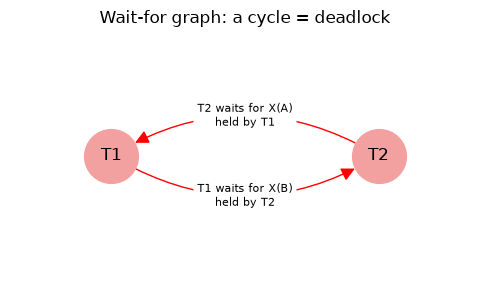

In [18]:
S_dead = "r1(A) r2(B) w1(B) w2(A) c1 c2"
print("No deadlock handling:")
r_none = simulate_2pl(S_dead, deadlock="none")
assert r_none["status"] == "deadlock"

edges, cyc = r_none["snapshots"][-1]
G = nx.DiGraph(); G.add_edges_from((f"T{a}", f"T{b}") for a, b in edges)
fig, ax = plt.subplots(figsize=(5, 3))
pos = {"T1": (0, 0), "T2": (1, 0)}
nx.draw_networkx(G, pos, node_color="#f2a0a0", node_size=1500, ax=ax, arrows=True, arrowsize=20,
                 connectionstyle="arc3,rad=0.3", edge_color="red")
nx.draw_networkx_edge_labels(G, pos, {("T1", "T2"): "T1 waits for X(B)\nheld by T2",
                                      ("T2", "T1"): "T2 waits for X(A)\nheld by T1"},
                             connectionstyle="arc3,rad=0.3", font_size=8, ax=ax)
ax.set_title("Wait-for graph: a cycle = deadlock"); ax.axis("off"); ax.margins(0.3)
plt.tight_layout(); plt.show()

In [19]:
results = {}
for policy in ["detect", "wait-die", "wound-wait", "timeout"]:
    print(f"\n--- {policy} ---")
    r = simulate_2pl(S_dead, deadlock=policy, timeout=2)
    aborted = r["trace"][r["trace"]["event"].str.startswith("ABORT")]
    results[policy] = {"aborted": ", ".join(f"T{int(t)}" for t in aborted["txn"]) or "-",
                       "executed schedule": show(r["final"])}
print(); print(pd.DataFrame(results).T.to_string())
assert results["wait-die"]["aborted"] == "T2" and results["wound-wait"]["aborted"] == "T2"
assert results["detect"]["aborted"] == "T2"


--- detect ---
                            T1                                            T2
tick                                                                        
1                    lock-S(A)                                              
1                        r1(A)                                              
2                                                                  lock-S(B)
2                                                                      r2(B)
3     WAIT for X(B) held by T2                                              
4                                                   WAIT for X(A) held by T1
4                               ABORT (deadlock T1→T2→T1, victim = youngest)
5                    lock-X(B)                                              
5                        w1(B)                                              
5                    unlock(A)                                              
5          commit + unlock all                              

**What just happened?** (T1 is older because it started first.)
- **No handling:** both wait forever; the wait-for graph has the cycle T1 → T2 → T1.
- **Detection:** the cycle is found when T2 starts waiting; the youngest, T2, is the victim.
- **Wait-die:** T1 (older) asks for B held by T2, so T1 *waits*. T2 (younger) asks for A held by T1, so T2 *dies*.
- **Wound-wait:** T1 (older) asks for B held by T2, so T1 *wounds* T2 immediately, before any cycle forms.
- **Timeout:** nothing is detected; the transaction that has waited long enough is aborted (here T1, the first to start waiting), and the other finishes.

In every case the executed schedule of committed transactions is serial-equivalent.

> 🎓 **Exam tip:** "wait-die: old waits, young dies; wound-wait: old wounds, young waits." In *both*, it is always the **younger** transaction that gets aborted.

## 8. Graph-based (tree) protocol and multiple-granularity locking

> 💡 **In plain English:** special locking rules for tree-shaped data, plus "intention" locks that make it cheap to lock either a whole table or a single row.

### 8.1 The tree protocol (briefly)

If data items are arranged in a tree (e.g. an index), a non-two-phase protocol can still guarantee serializability. **Tree protocol** rules (exclusive locks only):
1. A transaction's first lock may be on any node.
2. Afterwards, it may lock node X only if it currently holds a lock on X's **parent**.
3. Nodes may be unlocked at any time.
4. A node locked and unlocked by a transaction cannot be locked again by it.

Benefits: conflict serializable **and deadlock-free**, and locks are released early. Drawbacks: a transaction may lock nodes it does not need (to reach deeper ones), and schedules may be non-recoverable unless commit dependencies are tracked.

In [20]:
def follows_tree_protocol(ops, parent):
    "ops: list of ('L'|'U', node) for ONE transaction; parent: dict child -> parent."
    held, ever_locked = set(), set()
    for k, (action, node) in enumerate(ops):
        if action == "L":
            if node in ever_locked:
                return False, f"step {k+1}: relocks {node}"
            if ever_locked and parent.get(node) not in held:
                return False, f"step {k+1}: locks {node} without holding its parent {parent.get(node)}"
            held.add(node); ever_locked.add(node)
        else:
            held.discard(node)
    return True, "ok"

#        A
#      /   \
#     B     C
#    / \     \
#   D   E     F
parent = {"B": "A", "C": "A", "D": "B", "E": "B", "F": "C"}
ok_seq = [("L", "B"), ("L", "D"), ("L", "E"), ("U", "B"), ("U", "D"), ("U", "E")]
bad_parent = [("L", "B"), ("L", "D"), ("U", "B"), ("L", "E")]       # E's parent B was already released
bad_relock = [("L", "A"), ("L", "C"), ("U", "C"), ("L", "C")]       # C locked a second time
for ops in [ok_seq, bad_parent, bad_relock]:
    print(ops, "->", follows_tree_protocol(ops, parent))
assert follows_tree_protocol(ok_seq, parent)[0]
assert not follows_tree_protocol(bad_parent, parent)[0] and not follows_tree_protocol(bad_relock, parent)[0]

[('L', 'B'), ('L', 'D'), ('L', 'E'), ('U', 'B'), ('U', 'D'), ('U', 'E')] -> (True, 'ok')
[('L', 'B'), ('L', 'D'), ('U', 'B'), ('L', 'E')] -> (False, 'step 4: locks E without holding its parent B')
[('L', 'A'), ('L', 'C'), ('U', 'C'), ('L', 'C')] -> (False, 'step 4: relocks C')


### 8.2 Multiple-granularity locking

Locking a whole table row by row is slow (millions of locks); locking only whole tables kills concurrency. **Multiple granularity** organizes data as a tree (database → table/file → page → row) and lets a transaction lock at any level. Locking a node implicitly locks all its descendants. To make conflicts detectable at the top, **intention** locks are placed on all ancestors first:

| Mode | Meaning |
|---|---|
| **IS** (intention shared) | will take S locks somewhere below |
| **IX** (intention exclusive) | will take X (or S) locks somewhere below |
| **S** | the whole subtree is locked shared |
| **SIX** (shared + intention exclusive) | the whole subtree is read; some descendants will be written (e.g. scan a table and update a few rows) |
| **X** | the whole subtree is locked exclusive |

**Rules:** lock the root first; to lock a node in S or IS, hold IS or IX on its parent; to lock in X, IX or SIX, hold IX or SIX on its parent; locks are acquired top-down, released bottom-up, and the protocol is used with 2PL.

In [21]:
MODES = ["IS", "IX", "S", "SIX", "X"]
ok = {("IS", "IS"), ("IS", "IX"), ("IS", "S"), ("IS", "SIX"), ("IX", "IS"), ("IX", "IX"),
      ("S", "IS"), ("S", "S"), ("SIX", "IS")}
MGL = {(a, b): (a, b) in ok for a in MODES for b in MODES}            # (requested, held) -> compatible?
print(pd.DataFrame([["✓" if MGL[(r, h)] else "✗" for h in MODES] for r in MODES],
                   index=[f"request {m}" for m in MODES], columns=[f"held {m}" for m in MODES]).to_string())
assert all(MGL[(a, b)] == MGL[(b, a)] for a in MODES for b in MODES)   # the matrix is symmetric

def lock_path(path, mode):
    "Locks needed to lock the last node of `path` in `mode` (intention locks on all ancestors)."
    intent = "IS" if mode in ("S", "IS") else "IX"
    return [(node, intent) for node in path[:-1]] + [(path[-1], mode)]

def can_coexist(req_a, req_b):
    "Can two transactions hold these lock sets at the same time?"
    held = dict(req_a)
    clashes = [(n, held[n], m) for n, m in req_b if n in held and not MGL[(m, held[n])]]
    return not clashes, clashes

T_scan = lock_path(["db", "employee"], "S")                      # read the whole employee table
T_upd = lock_path(["db", "employee", "page7", "row42"], "X")     # update one row
T_other = lock_path(["db", "dept", "page1", "row3"], "X")        # update a row of another table
T_six = lock_path(["db", "employee"], "SIX")                     # scan employee, update some rows
print("\nscan employee :", T_scan); print("update row42  :", T_upd); print("update dept   :", T_other)
for name, a, b in [("scan vs update row42", T_scan, T_upd), ("scan vs update dept row", T_scan, T_other),
                   ("SIX vs another reader of a row", T_six, lock_path(["db", "employee", "page2", "row5"], "S"))]:
    print(f"{name:32s} ->", can_coexist(a, b))
assert not can_coexist(T_scan, T_upd)[0] and can_coexist(T_scan, T_other)[0]

            held IS held IX held S held SIX held X
request IS        ✓       ✓      ✓        ✓      ✗
request IX        ✓       ✓      ✗        ✗      ✗
request S         ✓       ✗      ✓        ✗      ✗
request SIX       ✓       ✗      ✗        ✗      ✗
request X         ✗       ✗      ✗        ✗      ✗

scan employee : [('db', 'IS'), ('employee', 'S')]
update row42  : [('db', 'IX'), ('employee', 'IX'), ('page7', 'IX'), ('row42', 'X')]
update dept   : [('db', 'IX'), ('dept', 'IX'), ('page1', 'IX'), ('row3', 'X')]
scan vs update row42             -> (False, [('employee', 'S', 'IX')])
scan vs update dept row          -> (True, [])
SIX vs another reader of a row   -> (True, [])


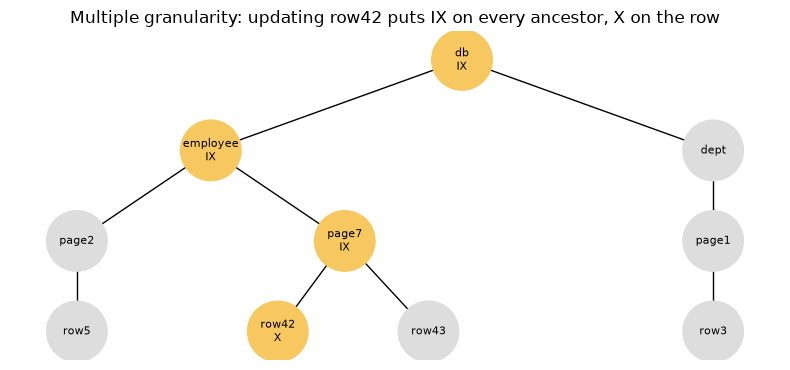

In [22]:
H = nx.DiGraph([("db", "employee"), ("db", "dept"), ("employee", "page2"), ("employee", "page7"),
                ("dept", "page1"), ("page2", "row5"), ("page7", "row42"), ("page7", "row43"), ("page1", "row3")])
pos = {"db": (3, 3), "employee": (1.5, 2), "dept": (4.5, 2), "page2": (0.7, 1), "page7": (2.3, 1),
       "page1": (4.5, 1), "row5": (0.7, 0), "row42": (1.9, 0), "row43": (2.8, 0), "row3": (4.5, 0)}
labels = {"db": "db\nIX", "employee": "employee\nIX", "page7": "page7\nIX", "row42": "row42\nX"}
fig, ax = plt.subplots(figsize=(8, 3.8))
nx.draw_networkx(H, pos, ax=ax, node_size=1900, font_size=8, arrows=False,
                 node_color=["#f6c85f" if n in labels else "#dddddd" for n in H],
                 labels={n: labels.get(n, n) for n in H})
ax.set_title("Multiple granularity: updating row42 puts IX on every ancestor, X on the row")
ax.axis("off"); plt.tight_layout(); plt.show()

**What just happened?** The full-table scan needs S on `employee`; the row update needs IX on `employee`. S and IX are incompatible, so the conflict is detected **at the table node** with two lock checks instead of checking millions of row locks. The update of a `dept` row only meets the scan at `db` (IS vs IX: compatible), so both run concurrently. SIX on `employee` still lets another transaction read rows below it (IS is compatible with SIX).

Databases also **escalate** many fine-grained locks into one coarse lock when a transaction holds too many (SQL Server, DB2 do this).

## 9. Timestamp-ordering protocol and Thomas' write rule

> 💡 **In plain English:** instead of locks, every transaction gets a start time, and the database rejects any step that would break that time order.

Instead of locks, give each transaction a unique **timestamp** TS(T) when it starts (older = smaller), and force the schedule to be equivalent to the **serial order of timestamps**. For each item X keep:
- **R-TS(X):** largest timestamp of any transaction that read X;
- **W-TS(X):** largest timestamp of any transaction that wrote X.

**Rules** for transaction T:

| operation | condition | action |
|---|---|---|
| read(X) | TS(T) < W-TS(X) (a younger transaction already wrote X) | **reject**: roll back T (restart with a new timestamp) |
| read(X) | otherwise | execute; R-TS(X) := max(R-TS(X), TS(T)) |
| write(X) | TS(T) < R-TS(X) (a younger transaction already read the old value) | **reject**: roll back T |
| write(X) | TS(T) < W-TS(X) (a younger transaction already wrote X) | basic TO: **reject**; **Thomas' write rule: ignore** this obsolete write |
| write(X) | otherwise | execute; W-TS(X) := TS(T) |

Properties: conflict serializable (in timestamp order) and **deadlock-free** (nobody waits); but long transactions may starve, and schedules may be non-recoverable unless commits are delayed (a strict variant buffers writes until commit). With Thomas' write rule, the schedules are view serializable (not always conflict serializable): the ignored write would have been overwritten anyway.

In [23]:
def timestamp_ordering(S, thomas=False, verbose=True):
    S = parse(S)
    ts = {t: k + 1 for k, t in enumerate(dict.fromkeys(o.txn for o in S))}   # start order = timestamp
    R_TS, W_TS = defaultdict(int), defaultdict(int)
    aborted, kept, rows = set(), [], []
    items = sorted({o.item for o in S if o.item})
    for o in S:
        t, X = o.txn, o.item
        if t in aborted:
            action = "skipped (T rolled back)"
        elif o.kind == "r":
            if ts[t] < W_TS[X]:
                aborted.add(t); action = f"REJECT: TS={ts[t]} < W-TS({X})={W_TS[X]} → roll back T{t}"
            else:
                R_TS[X] = max(R_TS[X], ts[t]); kept.append(o); action = "ok"
        elif o.kind == "w":
            if ts[t] < R_TS[X]:
                aborted.add(t); action = f"REJECT: TS={ts[t]} < R-TS({X})={R_TS[X]} → roll back T{t}"
            elif ts[t] < W_TS[X]:
                if thomas:
                    action = f"IGNORED (Thomas): TS={ts[t]} < W-TS({X})={W_TS[X]}"
                else:
                    aborted.add(t); action = f"REJECT: TS={ts[t]} < W-TS({X})={W_TS[X]} → roll back T{t}"
            else:
                W_TS[X] = ts[t]; kept.append(o); action = "ok"
        else:
            kept.append(o); action = "commit"
        rows.append({"op": op_str(o), "result": action,
                     **{f"R-TS({i})": R_TS[i] for i in items}, **{f"W-TS({i})": W_TS[i] for i in items}})
    if verbose:
        print(pd.DataFrame(rows, index=range(1, len(rows) + 1)).to_string())
    return [o for o in kept if o.txn not in aborted], aborted, ts

print("Silberschatz's example r1(Q) w2(Q) w1(Q) with basic timestamp ordering:")
kept, ab, _ = timestamp_ordering("r1(Q) w2(Q) w1(Q) c1 c2")
assert ab == {1}
print("\n... and with Thomas' write rule:")
kept, ab, _ = timestamp_ordering("r1(Q) w2(Q) w1(Q) c1 c2", thomas=True)
assert ab == set() and show(kept) == "r1(Q) w2(Q) c1 c2"
print("executed:", show(kept))

Silberschatz's example r1(Q) w2(Q) w1(Q) with basic timestamp ordering:
      op                                   result  R-TS(Q)  W-TS(Q)
1  r1(Q)                                       ok        1        0
2  w2(Q)                                       ok        1        2
3  w1(Q)  REJECT: TS=1 < W-TS(Q)=2 → roll back T1        1        2
4     c1                  skipped (T rolled back)        1        2
5     c2                                   commit        1        2

... and with Thomas' write rule:
      op                              result  R-TS(Q)  W-TS(Q)
1  r1(Q)                                  ok        1        0
2  w2(Q)                                  ok        1        2
3  w1(Q)  IGNORED (Thomas): TS=1 < W-TS(Q)=2        1        2
4     c1                              commit        1        2
5     c2                              commit        1        2
executed: r1(Q) w2(Q) c1 c2


In [24]:
# Randomized check: committed operations are conflict serializable IN TIMESTAMP ORDER
for thomas in (False, True):
    rolled_back = 0
    for trial in range(1000):
        S = random_schedule(n_txn=random.randint(2, 4), items="AB")
        kept, ab, ts = timestamp_ordering(S, thomas=thomas, verbose=False)
        nodes, edges = precedence_graph(kept)
        assert all(ts[a] < ts[b] for a, b in edges), show(S)          # every edge goes old -> young
        rolled_back += len(ab)
    print(f"Thomas={thomas}: 1,000 random schedules, all serializable in timestamp order; "
          f"{rolled_back} transaction roll-backs in total")

Thomas=False: 1,000 random schedules, all serializable in timestamp order; 564 transaction roll-backs in total


Thomas=True: 1,000 random schedules, all serializable in timestamp order; 500 transaction roll-backs in total


**What just happened?** In Silberschatz's example, T1 (TS = 1) tries to write Q after the younger T2 (TS = 2) wrote it. Basic TO rolls T1 back. Thomas' write rule notices that T2's write would overwrite T1's in the timestamp-order serial schedule T1, T2 anyway, so it simply drops w1(Q) and both commit. On random schedules every precedence edge of the executed operations goes from an older to a younger transaction, which is exactly "equivalent to the serial schedule in timestamp order"; Thomas' rule needs fewer roll-backs (see the counts).

## 10. Optimistic (validation-based) concurrency control and MVCC

> 💡 **In plain English:** optimistic methods let everyone work freely and check for clashes at the end; MVCC keeps old versions so readers never wait for writers.

### 10.1 Validation-based protocol

**Idea:** conflicts are rare, so do not lock anything; check for problems at the end. Each transaction runs in three phases:
1. **Read phase:** read from the database, write only to *private* copies.
2. **Validation phase:** check that applying the writes cannot break serializability.
3. **Write phase:** if validation succeeds, copy private writes into the database; otherwise abort and restart.

The timestamp of T is the time of its validation, TS(T) = Validation(T). Transaction T_j passes validation if for **every** T_i with TS(T_i) < TS(T_j), one of these holds:
1. Finish(T_i) < Start(T_j): T_i finished before T_j started (serial), or
2. Start(T_j) < Finish(T_i) < Validation(T_j) **and** WriteSet(T_i) ∩ ReadSet(T_j) = ∅: T_i's writes ended before T_j validates, and T_j did not read anything T_i wrote.

Good for read-mostly workloads; under high contention many transactions do all their work and then abort.

txn read set write set  valid?                                     reason
T25   [A, B]        []    True                     no earlier transaction
T26   [A, B]    [A, B]    True                              cond 2 vs T25
T27   [B, C]       [C]   False fails vs T26: Tj read ['B'] that T26 wrote
T28      [A]       [D]    True                              cond 1 vs T26


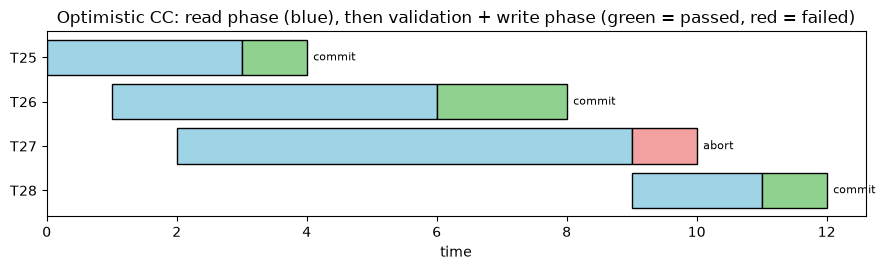

In [25]:
def validate_all(txns, verbose=True):
    "txns: dicts with name, start, validation, finish, reads, writes. Validate in validation order."
    passed, rows = [], []
    for Tj in sorted(txns, key=lambda t: t["validation"]):
        ok, why = True, "no earlier transaction"
        for Ti in passed:                                    # TS(Ti) < TS(Tj)
            if Ti["finish"] < Tj["start"]:
                why = f"cond 1 vs {Ti['name']}"
            elif Ti["finish"] < Tj["validation"] and not (Ti["writes"] & Tj["reads"]):
                why = f"cond 2 vs {Ti['name']}"
            else:
                ok = False
                why = f"fails vs {Ti['name']}: Tj read {sorted(Ti['writes'] & Tj['reads'])} that {Ti['name']} wrote" \
                      if Ti["writes"] & Tj["reads"] else f"fails vs {Ti['name']}: {Ti['name']} still writing"
                break
        if ok: passed.append(Tj)
        rows.append({"txn": Tj["name"], "read set": sorted(Tj["reads"]), "write set": sorted(Tj["writes"]),
                     "valid?": ok, "reason": why})
    if verbose: print(pd.DataFrame(rows).to_string(index=False))
    return {r["txn"]: r["valid?"] for r in rows}

occ = [dict(name="T25", start=0, validation=3, finish=4, reads={"A", "B"}, writes=set()),        # Silberschatz: read-only
       dict(name="T26", start=1, validation=6, finish=8, reads={"A", "B"}, writes={"A", "B"}),   # transfer
       dict(name="T27", start=2, validation=9, finish=10, reads={"B", "C"}, writes={"C"}),       # read B while T26 wrote it
       dict(name="T28", start=9, validation=11, finish=12, reads={"A"}, writes={"D"})]           # starts after T26 finished
outcome = validate_all(occ)
assert outcome == {"T25": True, "T26": True, "T27": False, "T28": True}

fig, ax = plt.subplots(figsize=(9, 2.8))
for k, t in enumerate(occ):
    ax.barh(k, t["validation"] - t["start"], left=t["start"], color="#9fd3e6", edgecolor="black")
    ax.barh(k, t["finish"] - t["validation"], left=t["validation"],
            color="#8fd18f" if outcome[t["name"]] else "#f2a0a0", edgecolor="black")
    ax.text(t["finish"] + 0.1, k, "commit" if outcome[t["name"]] else "abort", va="center", fontsize=8)
ax.set_yticks(range(len(occ))); ax.set_yticklabels([t["name"] for t in occ]); ax.invert_yaxis()
ax.set_xlabel("time"); ax.set_title("Optimistic CC: read phase (blue), then validation + write phase (green = passed, red = failed)")
plt.tight_layout(); plt.show()

**What just happened?** T25 (Silberschatz's read-only example) and T26 overlap, but T25 writes nothing, so T26 passes condition 2. T27 read B while T26 was still in its read/write phases and T26 wrote B, so T27 fails (it may have read the old B). T28 started after T26 finished, so condition 1 applies.

### 10.2 Multiversion concurrency control (MVCC)

**Idea:** never overwrite in place; every write creates a new **version** stamped with the writing transaction. A reader sees a **snapshot**: the latest version committed before it started. Hence **readers never block writers and writers never block readers**.

PostgreSQL stores versions in the table itself: each row version (tuple) carries `xmin` (the transaction that created it) and `xmax` (the one that deleted or replaced it), each query checks visibility against its snapshot, and `VACUUM` later removes versions no snapshot can see. Oracle, MySQL InnoDB and SQL Server (with snapshot isolation enabled) keep old versions in undo/version stores instead.

Snapshot reads plus the **first-committer-wins** rule for write-write conflicts give **snapshot isolation (SI)**, which PostgreSQL uses for `REPEATABLE READ`. SI prevents dirty reads, unrepeatable reads, phantoms and lost updates, but **not write skew**. PostgreSQL's `SERIALIZABLE` adds Serializable Snapshot Isolation (SSI, since version 9.1), which detects dangerous read-write patterns and aborts one transaction.

In [26]:
class SnapshotStore:
    "A tiny multiversion store with snapshot isolation and first-committer-wins."
    def __init__(self, data):
        self.clock = 0                                          # commit counter
        self.versions = {k: [(0, v)] for k, v in data.items()}  # key -> [(commit_ts, value), ...]
    def begin(self, name):
        return {"name": name, "snapshot": self.clock, "writes": {}}
    def read(self, tx, key):
        if key in tx["writes"]: return tx["writes"][key]        # read your own write
        return [v for ts, v in self.versions[key] if ts <= tx["snapshot"]][-1]
    def write(self, tx, key, value):
        tx["writes"][key] = value                               # private until commit
    def commit(self, tx):
        clash = [k for k in tx["writes"] if self.versions[k][-1][0] > tx["snapshot"]]
        if clash:                                               # someone committed a newer version first
            return f"{tx['name']} ABORTED (write-write conflict on {clash})"
        self.clock += 1
        for k, v in tx["writes"].items(): self.versions[k].append((self.clock, v))
        return f"{tx['name']} committed at ts={self.clock}"

db = SnapshotStore({"A": 100, "B": 50})
t1, t2 = db.begin("T1"), db.begin("T2")
print("T1 reads A =", db.read(t1, "A"))
db.write(t2, "A", 70); print(db.commit(t2))
print("T1 reads A again =", db.read(t1, "A"), "(its snapshot is stable: no unrepeatable read, and T2 never waited)")
assert db.read(t1, "A") == 100
print("a new transaction sees A =", db.read(db.begin("T3"), "A"))

print("\nLost update attempt under SI:")
t4, t5 = db.begin("T4"), db.begin("T5")
db.write(t4, "A", db.read(t4, "A") - 50); db.write(t5, "A", db.read(t5, "A") + 20)
print(" ", db.commit(t4)); r5 = db.commit(t5); print(" ", r5)
assert "ABORTED" in r5

print("\nWrite skew under SI (rule: at least one doctor must stay on call):")
oncall = SnapshotStore({"alice": True, "bob": True})
ta, tb = oncall.begin("Ta"), oncall.begin("Tb")
if oncall.read(ta, "alice") and oncall.read(ta, "bob"): oncall.write(ta, "alice", False)   # 'bob is on call, I can leave'
if oncall.read(tb, "alice") and oncall.read(tb, "bob"): oncall.write(tb, "bob", False)     # 'alice is on call, I can leave'
print(" ", oncall.commit(ta)); print(" ", oncall.commit(tb))
final = {d: oncall.read(oncall.begin("check"), d) for d in ["alice", "bob"]}
print("  on call now:", final, "-> nobody! SI allowed a non-serializable result")
assert final == {"alice": False, "bob": False}

T1 reads A = 100
T2 committed at ts=1
T1 reads A again = 100 (its snapshot is stable: no unrepeatable read, and T2 never waited)
a new transaction sees A = 70

Lost update attempt under SI:
  T4 committed at ts=2
  T5 ABORTED (write-write conflict on ['A'])

Write skew under SI (rule: at least one doctor must stay on call):
  Ta committed at ts=1
  Tb committed at ts=2
  on call now: {'alice': False, 'bob': False} -> nobody! SI allowed a non-serializable result


**What just happened?** T1 kept seeing A = 100 although T2 committed A = 70 in the middle, and neither waited for the other. Two concurrent read-modify-write transactions on A could not both commit (the second aborts, so no lost update). But in the on-call example the two transactions wrote *different* rows, each based on a snapshot that the other made false. Both committed and the business rule broke: **write skew**, the anomaly that separates snapshot isolation from true serializability.

## 11. SQL isolation levels

> 💡 **In plain English:** isolation levels are settings that trade safety for speed, and we see what SQLite really does when two connections share one file.

The SQL standard defines four isolation levels by the anomalies (it calls them *phenomena*) they allow:

| Isolation level | Dirty read | Non-repeatable read | Phantom |
|---|---|---|---|
| **READ UNCOMMITTED** | possible | possible | possible |
| **READ COMMITTED** | prevented | possible | possible |
| **REPEATABLE READ** | prevented | prevented | possible |
| **SERIALIZABLE** | prevented | prevented | prevented |

Real systems differ from the table, so always read your DBMS's documentation:

| DBMS | Default | Notes |
|---|---|---|
| PostgreSQL | READ COMMITTED | MVCC; READ UNCOMMITTED behaves as READ COMMITTED; REPEATABLE READ is snapshot isolation (no phantoms, but write skew possible); SERIALIZABLE is SSI |
| MySQL (InnoDB) | REPEATABLE READ | MVCC snapshots for plain reads; next-key (record + gap) locks for locking reads and writes |
| Oracle | READ COMMITTED | MVCC; offers READ COMMITTED and SERIALIZABLE (which is snapshot isolation) |
| SQL Server | READ COMMITTED | lock-based by default; optional row versioning (READ_COMMITTED_SNAPSHOT, SNAPSHOT) |
| SQLite | SERIALIZABLE | one writer at a time for the whole database file; readers see committed data only |

Lower levels allow more concurrency; the anomalies they allow must then be handled by the application (for example `SELECT … FOR UPDATE`, or retry loops).

### SQLite with two connections

SQLite locks the **whole database file**. In the default rollback-journal mode a writer first takes a RESERVED lock (others may still read the old data), then an EXCLUSIVE lock to commit (which needs all readers to finish). A connection that cannot get a lock waits up to its **busy timeout** (the `timeout=` argument of `sqlite3.connect`, 5 seconds by default) and then raises `sqlite3.OperationalError: database is locked`. Below we use a 0.2 s timeout so the demo is quick.

In [27]:
lock_path = os.path.join(WORKDIR, "locks.db")
c1 = sqlite3.connect(lock_path, isolation_level=None, timeout=0.2)   # isolation_level=None: we write BEGIN/COMMIT
c2 = sqlite3.connect(lock_path, isolation_level=None, timeout=0.2)
c1.execute("CREATE TABLE acc (name TEXT PRIMARY KEY, bal INTEGER)")
c1.execute("INSERT INTO acc VALUES ('A', 100), ('B', 50)")
read_A = lambda c: c.execute("SELECT bal FROM acc WHERE name = 'A'").fetchone()[0]
print("journal mode:", c1.execute("PRAGMA journal_mode").fetchone()[0])

c1.execute("BEGIN IMMEDIATE")                                   # take the write lock now
c1.execute("UPDATE acc SET bal = bal - 50 WHERE name = 'A'")
print("1) c1 changed A to 50 (uncommitted); c2 reads A =", read_A(c2), "-> no dirty read")
assert read_A(c2) == 100
t0 = time.perf_counter()
try:
    c2.execute("BEGIN IMMEDIATE")                               # a second writer
except sqlite3.OperationalError as e:
    print(f"2) c2 tries to write: OperationalError '{e}' after {time.perf_counter() - t0:.1f} s (busy timeout)")
c1.execute("COMMIT")
print("3) after c1 commits, c2 reads A =", read_A(c2))

c2.execute("BEGIN"); print("4) c2 starts a read transaction, reads A =", read_A(c2))   # holds a SHARED lock
c1.execute("BEGIN IMMEDIATE"); c1.execute("UPDATE acc SET bal = bal + 1 WHERE name = 'A'")
try:
    c1.execute("COMMIT")                                        # needs EXCLUSIVE: blocked by c2's SHARED lock
except sqlite3.OperationalError as e:
    print(f"5) c1 cannot COMMIT while c2 is reading: '{e}' (c1 is still in its transaction: {c1.in_transaction})")
c2.execute("COMMIT"); c1.execute("COMMIT")                      # reader done -> the commit now succeeds
print("6) after the reader finished, c1's retried COMMIT worked: A =", read_A(c2))
assert read_A(c2) == 51

journal mode: delete
1) c1 changed A to 50 (uncommitted); c2 reads A = 100 -> no dirty read


2) c2 tries to write: OperationalError 'database is locked' after 0.2 s (busy timeout)


3) after c1 commits, c2 reads A = 50
4) c2 starts a read transaction, reads A = 50


5) c1 cannot COMMIT while c2 is reading: 'database is locked' (c1 is still in its transaction: True)
6) after the reader finished, c1's retried COMMIT worked: A = 51


In [28]:
print("A DEADLOCK in rollback-journal mode: two DEFERRED transactions both read, then both try to write")
c1.execute("BEGIN"); c2.execute("BEGIN")
read_A(c1); read_A(c2)                                          # both hold SHARED locks
c1.execute("UPDATE acc SET bal = bal + 5 WHERE name = 'A'")     # c1 gets RESERVED
for who, conn, sql in [("c2 UPDATE", c2, "UPDATE acc SET bal = bal + 7 WHERE name = 'B'"),   # needs RESERVED (c1 has it)
                       ("c1 COMMIT", c1, "COMMIT")]:                                         # needs c2's SHARED gone
    t0 = time.perf_counter()
    try:
        conn.execute(sql)
    except sqlite3.OperationalError as e:
        print(f"  {who}: '{e}' after {time.perf_counter() - t0:.2f} s")
print("  each waits for the other: c2 cannot write while c1 holds RESERVED, c1 cannot commit while c2 reads")
c2.execute("ROLLBACK")                                          # the victim backs off ...
c1.execute("COMMIT")                                            # ... and c1 can finish
print("  after c2 rolled back, c1 committed: A =", read_A(c2))
assert read_A(c2) == 56
print("  lesson: start write transactions with BEGIN IMMEDIATE, so the conflict happens up front")

A DEADLOCK in rollback-journal mode: two DEFERRED transactions both read, then both try to write
  c2 UPDATE: 'database is locked' after 0.00 s


  c1 COMMIT: 'database is locked' after 0.21 s
  each waits for the other: c2 cannot write while c1 holds RESERVED, c1 cannot commit while c2 reads
  after c2 rolled back, c1 committed: A = 56
  lesson: start write transactions with BEGIN IMMEDIATE, so the conflict happens up front


In [29]:
print("WAL mode: readers and the writer no longer block each other")
print("journal mode:", c1.execute("PRAGMA journal_mode = WAL").fetchone()[0])
c2.execute("BEGIN"); before = read_A(c2)                        # c2's snapshot starts here
c1.execute("BEGIN IMMEDIATE"); c1.execute("UPDATE acc SET bal = 999 WHERE name = 'A'"); c1.execute("COMMIT")
during = read_A(c2)
print(f"  c1 committed A = 999 while c2 was reading; inside its transaction c2 still sees {before} then {during}")
c2.execute("COMMIT")
print("  a new transaction of c2 sees", read_A(c2))
assert before == during == 56 and read_A(c2) == 999

WAL mode: readers and the writer no longer block each other
journal mode: wal
  c1 committed A = 999 while c2 was reading; inside its transaction c2 still sees 56 then 56
  a new transaction of c2 sees 999


In [30]:
def with_retry(fn, attempts=8, base_delay=0.05):
    "Run fn(); on 'database is locked' wait with exponential backoff and try again."
    for k in range(1, attempts + 1):
        try:
            return fn(), k
        except sqlite3.OperationalError as e:
            if "locked" not in str(e) or k == attempts:
                raise                                                       # not a lock problem, or give up
            time.sleep(base_delay * 2 ** (k - 1))                           # 0.05, 0.1, 0.2, ... seconds

locked = threading.Event()
def long_writer(path, seconds):
    "Another program that holds the write lock for a while."
    c = sqlite3.connect(path, isolation_level=None)
    c.execute("BEGIN IMMEDIATE"); c.execute("UPDATE acc SET bal = bal + 1 WHERE name = 'B'")
    locked.set()                                                            # tell the main thread
    time.sleep(seconds); c.execute("COMMIT"); c.close()

def deposit():
    c = sqlite3.connect(lock_path, isolation_level=None, timeout=0.05)
    try:
        c.execute("BEGIN IMMEDIATE"); c.execute("UPDATE acc SET bal = bal + 100 WHERE name = 'A'"); c.execute("COMMIT")
    finally:
        c.close()

th = threading.Thread(target=long_writer, args=(lock_path, 0.6)); th.start(); locked.wait(5)
t0 = time.perf_counter()
_, tries = with_retry(deposit)
th.join()
print(f"deposit succeeded on attempt {tries} after {time.perf_counter() - t0:.2f} s; A = {read_A(c1)}")
assert read_A(c1) == 1099 and tries > 1
c1.close(); c2.close()

deposit succeeded on attempt 5 after 0.97 s; A = 1099


**What just happened?**
1. While c1 had an uncommitted change, c2 still read the committed value 100: SQLite never shows dirty data.
2. A second writer waited for the busy timeout and got `database is locked`: one writer at a time.
3. In rollback-journal mode an open **reader** blocked the writer's `COMMIT`; the writer stayed in its transaction and could simply retry the `COMMIT` after the reader finished.
4. Two `DEFERRED` transactions that both read and then both write form a real deadlock: c2 cannot get the write lock and c1 cannot commit. SQLite reports `database is locked` (without waiting, or after the busy timeout, as the printed times show); one of them must roll back, then the other commits. `BEGIN IMMEDIATE` avoids this pattern.
5. In **WAL** mode the reader kept its snapshot (56) while the writer committed 999: like MVCC, with one writer at a time.
6. `with_retry` handled a busy database gracefully: it backed off exponentially until the other writer finished (the attempt count and time depend on your machine).

> ⚠️ **Common mistake:** catching `database is locked` and retrying only the last statement. Retry the **whole transaction** (as `with_retry(deposit)` does); its earlier reads may be stale.

In [31]:
con.close()                                    # close the bank connection from Section 1
shutil.rmtree(WORKDIR)                         # clean up all temporary database files
print("temporary files removed:", not os.path.exists(WORKDIR))

temporary files removed: True


## Comparison of concurrency-control methods

> 💡 **In plain English:** one table comparing every method in this notebook, for quick revision.

| Method | Serializable? | Deadlocks? | Cascading aborts? | Readers block writers? | Best for |
|---|---|---|---|---|---|
| Basic 2PL | conflict serializable | yes | possible | yes | (teaching) |
| Strict 2PL | conflict serializable, strict | yes | no | yes | general OLTP (classic lock-based DBMSs) |
| Rigorous 2PL | serializable in commit order | yes | no | yes | simple recovery, distributed commit |
| Tree protocol | conflict serializable | **no** | possible | yes | tree-structured data (indexes) |
| Timestamp ordering | conflict serializable (TS order) | **no** (no waiting) | possible unless strict TO | no locks | low-contention workloads |
| TO + Thomas' rule | view serializable | no | possible | no locks | blind-write-heavy workloads |
| Optimistic (validation) | conflict serializable | no | no (writes are private) | no | read-mostly, low contention |
| MVCC / snapshot isolation | **no** (write skew), SSI makes it serializable | write-write waits only | no | **no** | mixed read/write workloads (PostgreSQL, Oracle, InnoDB) |

## 🔗 How this connects to modern AI

> 💡 **In plain English:** feature stores, experiment trackers, data lakes and multi-agent AI systems all need transactions to keep shared data correct.

- **Feature stores and online inference.** An online feature store must never serve a half-written feature vector; per-entity atomic writes (and snapshot reads) are transactions in disguise. See [Feature stores](../../15_MLOps/12_feature_stores.ipynb).
- **Experiment tracking and model registries.** Tools such as MLflow keep runs and model versions in a SQL database (often SQLite locally, which is why parallel hyperparameter-search workers can hit `database is locked`, and why the usual fix is a server database such as PostgreSQL). See [MLflow](../../15_MLOps/01_experiment_tracking/01_mlflow.ipynb) and [Model registry](../../15_MLOps/05_model_registry/01_model_registry.ipynb).
- **Data versioning and lakehouses.** Delta Lake and Apache Iceberg give data lakes ACID commits using **optimistic concurrency** (the validation idea of Section 10.1) and **snapshots** (MVCC), so a training job reads a consistent version while new data lands. See [Data versioning](../../15_MLOps/02_data_versioning/01_dvc.ipynb) and [Data engineering](../06_data_engineering/01_data_engineering.ipynb).
- **Vector databases for RAG.** Inserting and deleting embeddings while queries run is the same readers-vs-writers problem; many vector stores choose snapshot or eventual-consistency semantics. See [Vector databases](../03_vector_db/01_vector_databases.ipynb).
- **Multi-agent LLM systems.** Agents that read shared state, think, and write back face lost updates and write skew; use compare-and-set (optimistic) writes or a transactional store. See [Databases in AI](../05_db_in_ai/01_databases_in_ai.ipynb).

## Recap

> 💡 **In plain English:** the key ideas in a few bullets, for quick revision before the practice problems.

- A **transaction** is all-or-nothing; **ACID** = atomicity, consistency, isolation, durability. SQLite's journal undid a half-finished transaction after a real crash, and kept committed data after a crash.
- Operations **conflict** when they touch the same item from different transactions and one is a write (RW, WR, WW). Uncontrolled interleaving causes **lost updates, dirty reads, unrepeatable reads and phantoms**.
- **Conflict serializable** ⇔ acyclic **precedence graph**; a topological order is an equivalent serial order. **View serializability** is broader (blind writes) but NP-complete to test.
- **Strict ⊂ cascadeless ⊂ recoverable**, independent of serializability.
- **2PL** (growing then shrinking phase) ⇒ conflict serializable. **Strict 2PL** also gives strict schedules; **rigorous 2PL** also gives commit-order serializability. Locking brings **deadlocks**: detect (wait-for graph) or prevent (**wait-die**, **wound-wait**), or use timeouts.
- **Intention locks** (IS, IX, SIX) make multiple-granularity locking efficient. The **tree protocol** is deadlock-free without being two-phase.
- **Timestamp ordering** never waits (no deadlocks); **Thomas' write rule** drops obsolete writes. **Optimistic CC** validates at commit; **MVCC** lets readers and writers proceed in parallel but plain snapshot isolation allows **write skew**.
- SQL **isolation levels** trade anomalies for concurrency; check what your DBMS really does. SQLite: one writer, busy timeout, `database is locked`, retry the whole transaction.

## Practice problems

**1. (Easy)** Is `r1(A) r2(A) w1(A) w2(A)` conflict serializable? Which anomaly is it?
<details><summary>Show solution</summary>

r1(A) before w2(A) gives T1 → T2; r2(A) before w1(A) gives T2 → T1. Cycle, so **not** conflict serializable. It is the **lost update** pattern. `conflict_serializable("r1(A) r2(A) w1(A) w2(A)")` returns `(False, [1, 2])`.
</details>

**2. (Easy)** Classify `r1(X) w1(X) r2(X) c2 c1` as not recoverable / recoverable / cascadeless / strict.
<details><summary>Show solution</summary>

T2 reads X written by uncommitted T1 and commits before T1: **not recoverable**. Swapping the commits (`… c1 c2`) makes it recoverable but still not cascadeless (dirty read).
</details>

**3. (Easy)** Which isolation level prevents dirty reads but allows non-repeatable reads? What is PostgreSQL's default?
<details><summary>Show solution</summary>

READ COMMITTED, which is also PostgreSQL's default.
</details>

**4. (Medium)** TS(T1) = 5, TS(T2) = 10. T2 holds a lock that T1 requests. What happens under wait-die and under wound-wait? And if T2 requests a lock held by T1?
<details><summary>Show solution</summary>

T1 is older. T1 requests from T2: wait-die → T1 **waits**; wound-wait → T1 **wounds** T2 (T2 aborts). T2 requests from T1: wait-die → T2 **dies**; wound-wait → T2 **waits**.
</details>

**5. (Medium)** Under basic timestamp ordering with TS(T1) = 1 < TS(T2) = 2, what happens in `r2(X) w1(X)`? And in `w2(X) r1(X)`?
<details><summary>Show solution</summary>

`r2(X)` sets R-TS(X) = 2. `w1(X)`: TS(T1) = 1 < R-TS(X) = 2 → **T1 is rolled back** (a younger transaction already read the old value). In `w2(X) r1(X)`: W-TS(X) = 2 > TS(T1) = 1 → T1's read is rejected, **T1 is rolled back**. Thomas' write rule does not help in either case (it only concerns write-after-write).
</details>

**6. (Medium)** Explain why 2PL guarantees conflict serializability.
<details><summary>Show solution</summary>

Suppose the precedence graph has an edge T_i → T_j: some operation of T_i conflicts with a later one of T_j on item X. T_j could only get its lock on X after T_i released its lock on X, and T_i, being two-phase, acquired all its locks before releasing any. So lock-point(T_i) < lock-point(T_j). Every edge therefore goes from an earlier to a later lock point, so the graph cannot contain a cycle, and ordering transactions by lock point gives an equivalent serial schedule. ∎
</details>

**7. (Coding)** Write `all_serial_orders(S)` that returns *every* serial order conflict equivalent to schedule `S` (all topological sorts of the precedence graph).
<details><summary>Show solution</summary>

```python
def all_serial_orders(S):
    nodes, edges = precedence_graph(S)
    return [list(p) for p in permutations(nodes)
            if all(p.index(a) < p.index(b) for a, b in edges)]

print(all_serial_orders("r1(X) r2(Y) w3(Z) w1(X) r3(X)"))   # T1 must precede T3; T2 is free
# [[1, 2, 3], [1, 3, 2], [2, 1, 3]]
```
</details>

**8. (Hard, coding)** Using `simulate_2pl`, find a schedule of two transactions on which **wound-wait** aborts a transaction but **wait-die** does not.
<details><summary>Show solution</summary>

Make the *older* transaction request a lock held by the younger one, with no request in the other direction. Wound-wait wounds the younger holder; wait-die lets the older one wait. The younger one must hold an **exclusive** lock (strict 2PL may release a shared lock early, before the older one asks).

```python
S = "r1(B) w2(A) w1(A) c2 c1"   # T1 appears first, so it is older; it requests X(A) held by T2
print(simulate_2pl(S, deadlock="wound-wait", verbose=False)["aborts"],   # 1
      simulate_2pl(S, deadlock="wait-die", verbose=False)["aborts"])     # 0
```
</details>

## Further reading

- Silberschatz, Korth and Sudarshan, *Database System Concepts*, 7th ed., Chapter 17 "Transactions" (ACID, states, serializability, recoverability, isolation levels) and Chapter 18 "Concurrency Control" (locking, deadlocks, multiple granularity, timestamps, validation, multiversion, snapshot isolation).
- Elmasri and Navathe, *Fundamentals of Database Systems*, 7th ed., Chapter 20 "Introduction to Transaction Processing Concepts and Theory" and Chapter 21 "Concurrency Control Techniques".
- Berenson et al., "A Critique of ANSI SQL Isolation Levels", SIGMOD 1995 (why the standard's table is not enough; introduces snapshot isolation anomalies).
- PostgreSQL documentation, chapter "Concurrency Control" (MVCC, isolation levels, SSI) and SQLite documentation pages "File Locking And Concurrency In SQLite Version 3" and "Write-Ahead Logging" (free online).
- GeeksforGeeks DBMS tutorial, sections on transactions, schedules, serializability, 2PL, deadlocks and timestamp ordering (many solved GATE questions).

## Next notebook

Continue with [06_recovery_and_storage.ipynb](06_recovery_and_storage.ipynb), which covers the log-based recovery that makes atomicity and durability work. For practical, everyday transaction code, revisit [SQL fundamentals](../01_sql/01_sql_fundamentals.ipynb).